# Partie C : Fine-tuning et apprentissage few-shot

## Qestion 9 : Fine-tuning de TTM sur les données locales

Dans la Question 7, on a évalué **Tiny Time Mixers (TTM)** en zero-shot : le modèle pré-entraîné a été appliqué directement à notre série de production éolienne sans mettre à jour ses paramètres.

On cherche maintenant à savoir si une adaptation aux données locales permet d'améliorer ses prévisions.

L'énoncé impose un fine-tuning partiel :

- le **tronc du modèle pré-entraîné reste gelé** ;
- seule la **tête de prédiction est entraînée** sur les données locales.

L'objectif est de conserver les représentations temporelles apprises pendant le pré-entraînement de TTM tout en adaptant sa sortie à notre série.

### Protocole

On conserve le découpage chronologique défini précédemment :

- **train** : apprentissage de la tête de prédiction ;
- **validation** : contrôle et choix des paramètres du fine-tuning ;
- **test** : évaluation finale uniquement.

Le jeu de test n'est donc pas utilisé pour entraîner le modèle ni pour sélectionner les hyperparamètres.

Pour rester cohérent avec la Q7, on conserve le même modèle TTM et le même principe de prévision à une heure :

$$
h=1.
$$

La performance finale sera évaluée avec la même échelle MASE calculée sur l'entraînement :

$$
\text{échelle MASE}=4996,19\text{ MW}.
$$

On comparera finalement :

$$
MASE_{\text{TTM zero-shot}}=0,188,
$$

$$
MASE_{\text{Gradient Boosting}}=0,120,
$$

et :

$$
MASE_{\text{TTM fine-tuné}}= ?
$$

On calculera également le gain relatif du fine-tuning par rapport au TTM zero-shot afin de déterminer si l'adaptation locale apporte une amélioration mesurable.

L'objectif n'est pas nécessairement de battre le Gradient Boosting, mais de déterminer si **l'adaptation de la tête de TTM aux données locales améliore réellement les performances par rapport au même modèle utilisé en zero-shot**.

In [1]:
# ============================================================
# Q9 — Chargement du même modèle TTM que dans la Q7
# ============================================================

from time import perf_counter
import torch

from tsfm_public.toolkit.get_model import get_model

MODEL_PATH = "ibm-granite/granite-timeseries-ttm-r2"

debut = perf_counter()

ttm_model = get_model(
    MODEL_PATH,
    context_length=1536,
    prediction_length=96,
)

duree = perf_counter() - debut

print("--- TTM chargé pour la Q9 ---")
print("Type :", type(ttm_model).__name__)
print("Context length :", ttm_model.config.context_length)
print("Prediction length :", ttm_model.config.prediction_length)
print(
    "Prediction filter length :",
    ttm_model.config.prediction_filter_length
)
print(f"Durée de chargement : {duree:.2f} s")

INFO:p-21588:t-4124:get_model.py:get_model:Loading model from: ibm-granite/granite-timeseries-ttm-r2
INFO:p-21588:t-4124:get_model.py:get_model:Model loaded successfully from ibm-granite/granite-timeseries-ttm-r2, revision = 1536-96-r2.
INFO:p-21588:t-4124:get_model.py:get_model:[TTM] context_length = 1536, prediction_length = 96


--- TTM chargé pour la Q9 ---
Type : TinyTimeMixerForPrediction
Context length : 1536
Prediction length : 96
Prediction filter length : None
Durée de chargement : 0.93 s


In [2]:
# ============================================================
# Q9 — Inspection de la structure du modèle TTM
# ============================================================

print("Type du modèle :")
print(type(ttm_model))

print("\n--- Modules principaux ---")
for nom, module in ttm_model.named_children():
    print(f"{nom:30s} -> {type(module).__name__}")

print("\n--- Configuration importante ---")
print("Context length :", ttm_model.config.context_length)
print("Prediction length :", ttm_model.config.prediction_length)
print(
    "Prediction filter length :",
    ttm_model.config.prediction_filter_length
)

# ------------------------------------------------------------
# Comptage des paramètres AVANT tout gel
# ------------------------------------------------------------

nb_total = sum(
    p.numel()
    for p in ttm_model.parameters()
)

nb_entrainables = sum(
    p.numel()
    for p in ttm_model.parameters()
    if p.requires_grad
)

print("\n--- Paramètres avant gel ---")
print(f"Paramètres totaux       : {nb_total:,}")
print(f"Paramètres entraînables : {nb_entrainables:,}")

print("\n--- Paramètres contenant 'head' ---")

for nom, param in ttm_model.named_parameters():

    if "head" in nom.lower():
        print(
            f"{nom:70s} "
            f"shape={str(tuple(param.shape)):18s} "
            f"requires_grad={param.requires_grad}"
        )

Type du modèle :
<class 'tsfm_public.models.tinytimemixer.modeling_tinytimemixer.TinyTimeMixerForPrediction'>

--- Modules principaux ---
backbone                       -> TinyTimeMixerModel
decoder                        -> TinyTimeMixerDecoder
head                           -> TinyTimeMixerForPredictionHead

--- Configuration importante ---
Context length : 1536
Prediction length : 96
Prediction filter length : None

--- Paramètres avant gel ---
Paramètres totaux       : 3,081,120
Paramètres entraînables : 3,081,120

--- Paramètres contenant 'head' ---
head.base_forecast_block.weight                                        shape=(96, 3072)         requires_grad=True
head.base_forecast_block.bias                                          shape=(96,)              requires_grad=True


In [3]:
# ============================================================
# Q9 — Gel du tronc et entraînement de la tête uniquement
# ============================================================

# ------------------------------------------------------------
# 1. Gel de tous les paramètres du modèle
# ------------------------------------------------------------

for param in ttm_model.parameters():
    param.requires_grad = False

# ------------------------------------------------------------
# 2. Réactivation uniquement de la tête de prédiction
# ------------------------------------------------------------

for param in ttm_model.head.parameters():
    param.requires_grad = True


# ------------------------------------------------------------
# 3. Comptage des paramètres
# ------------------------------------------------------------

nb_total = sum(
    p.numel()
    for p in ttm_model.parameters()
)

nb_entrainables = sum(
    p.numel()
    for p in ttm_model.parameters()
    if p.requires_grad
)

nb_geles = nb_total - nb_entrainables

pourcentage_entrainable = (
    100 * nb_entrainables / nb_total
)


# ------------------------------------------------------------
# 4. Affichage
# ------------------------------------------------------------

print("--- Configuration du fine-tuning ---")

print(f"Paramètres totaux       : {nb_total:,}")
print(f"Paramètres gelés        : {nb_geles:,}")
print(f"Paramètres entraînables : {nb_entrainables:,}")

print(
    "Part entraînable       : "
    f"{pourcentage_entrainable:.2f} %"
)

print("\n--- Paramètres encore entraînables ---")

for nom, param in ttm_model.named_parameters():

    if param.requires_grad:

        print(
            f"{nom:75s} "
            f"shape={str(tuple(param.shape)):20s}"
        )

--- Configuration du fine-tuning ---
Paramètres totaux       : 3,081,120
Paramètres gelés        : 2,786,112
Paramètres entraînables : 295,008
Part entraînable       : 9.57 %

--- Paramètres encore entraînables ---
head.base_forecast_block.weight                                             shape=(96, 3072)          
head.base_forecast_block.bias                                               shape=(96,)               


### Gel du modèle et paramètres entraînables

Le modèle TTM utilisé contient au total **3 081 120 paramètres**.

Pour respecter le protocole de la Q9, on gèle l'ensemble du modèle puis on réactive uniquement les paramètres appartenant à la tête de prédiction (`head`).

Après cette opération :

- **2 786 112 paramètres sont gelés** ;
- **295 008 paramètres restent entraînables** ;
- la partie entraînable représente seulement **9,57 % du modèle**.

Les seuls paramètres qui seront mis à jour pendant le fine-tuning sont les poids et le biais de la couche :

`head.base_forecast_block`

Le backbone et le decoder conservent donc leurs paramètres pré-entraînés.

Cette stratégie permet d'adapter la sortie du TTM à notre série de production éolienne tout en conservant les représentations temporelles apprises lors du pré-entraînement et en limitant fortement le nombre de paramètres à optimiser.

In [4]:
# ============================================================
# Q9 — Localisation du fichier de données
# ============================================================

from pathlib import Path

nom_fichier = "time_series_60min_singleindex.csv"

# Recherche à partir du dossier courant et de ses parents
candidats = []

dossier = Path.cwd()

for base in [dossier, *dossier.parents]:
    chemin = base / "data" / "raw" / nom_fichier
    
    if chemin.exists():
        candidats.append(chemin)

print("Dossier courant :", Path.cwd())

if candidats:
    DATA_PATH = candidats[0]
    print("Fichier trouvé  :", DATA_PATH)
else:
    print("Fichier non trouvé.")

Dossier courant : c:\Users\Said O\Desktop\Projets\TSFM_Wind_Forecasting
Fichier trouvé  : c:\Users\Said O\Desktop\Projets\TSFM_Wind_Forecasting\data\raw\time_series_60min_singleindex.csv


In [5]:
# =====================================================================================================
# Q9 — Chargement des données nécessaires et reconstruction du découpage chronologique de la Partie A
# =====================================================================================================

import pandas as pd

TARGET = "DE_wind_onshore_generation_actual"

# ------------------------------------------------------------
# 1. Chargement uniquement des deux colonnes nécessaires
# ------------------------------------------------------------

data = pd.read_csv(
    DATA_PATH,
    usecols=["utc_timestamp", TARGET]
)

# Conversion de la date en datetime UTC
data["utc_timestamp"] = pd.to_datetime(
    data["utc_timestamp"],
    utc=True
)

# Tri chronologique par sécurité
data = (
    data
    .sort_values("utc_timestamp")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 2. Reconstruction du même découpage 70 % / 15 % / 15 %
# ------------------------------------------------------------

n = len(data)

n_train = int(0.70 * n)
n_validation = int(0.15 * n)

train = data.iloc[:n_train].copy()

validation = data.iloc[
    n_train:n_train + n_validation
].copy()

test = data.iloc[
    n_train + n_validation:
].copy()


# ------------------------------------------------------------
# 3. Vérifications
# ------------------------------------------------------------

print("--- Données complètes ---")
print(f"Nombre d'observations : {len(data):,}")
print(
    "Période :",
    data["utc_timestamp"].iloc[0],
    "→",
    data["utc_timestamp"].iloc[-1]
)

print("\n--- Découpage chronologique ---")

for nom, df_partie in [
    ("Train", train),
    ("Validation", validation),
    ("Test", test)
]:
    print(
        f"{nom:12s} : {len(df_partie):,} observations | "
        f"{df_partie['utc_timestamp'].iloc[0]} "
        f"→ {df_partie['utc_timestamp'].iloc[-1]}"
    )

print("\n--- Valeurs manquantes de la cible ---")
print(f"Train       : {train[TARGET].isna().sum()}")
print(f"Validation  : {validation[TARGET].isna().sum()}")
print(f"Test        : {test[TARGET].isna().sum()}")

--- Données complètes ---
Nombre d'observations : 50,401
Période : 2014-12-31 23:00:00+00:00 → 2020-09-30 23:00:00+00:00

--- Découpage chronologique ---
Train        : 35,280 observations | 2014-12-31 23:00:00+00:00 → 2019-01-09 22:00:00+00:00
Validation   : 7,560 observations | 2019-01-09 23:00:00+00:00 → 2019-11-20 22:00:00+00:00
Test         : 7,561 observations | 2019-11-20 23:00:00+00:00 → 2020-09-30 23:00:00+00:00

--- Valeurs manquantes de la cible ---
Train       : 73
Validation  : 0
Test        : 0


In [6]:
# ============================================================
# Q9 — Vérification d'une fenêtre valide avant fine-tuning
# ============================================================

import numpy as np
import torch

CONTEXT_LENGTH = 1536
PREDICTION_LENGTH = 96

serie_train = train[TARGET].to_numpy(dtype=np.float32)

# ------------------------------------------------------------
# Recherche de la première fenêtre sans valeur manquante
# ------------------------------------------------------------

indice_valide = None

for i in range(
    len(serie_train) - CONTEXT_LENGTH - PREDICTION_LENGTH + 1
):
    contexte = serie_train[
        i:i + CONTEXT_LENGTH
    ]

    futur = serie_train[
        i + CONTEXT_LENGTH:
        i + CONTEXT_LENGTH + PREDICTION_LENGTH
    ]

    if not np.isnan(contexte).any() and not np.isnan(futur).any():
        indice_valide = i
        break

if indice_valide is None:
    raise ValueError("Aucune fenêtre valide trouvée.")

# ------------------------------------------------------------
# Construction de la fenêtre test
# ------------------------------------------------------------

past_values = serie_train[
    indice_valide:
    indice_valide + CONTEXT_LENGTH
]

future_values = serie_train[
    indice_valide + CONTEXT_LENGTH:
    indice_valide + CONTEXT_LENGTH + PREDICTION_LENGTH
]

x = torch.tensor(
    past_values,
    dtype=torch.float32
).reshape(1, CONTEXT_LENGTH, 1)

y = torch.tensor(
    future_values,
    dtype=torch.float32
).reshape(1, PREDICTION_LENGTH, 1)

# ------------------------------------------------------------
# Vérifications
# ------------------------------------------------------------

print("--- Fenêtre sélectionnée ---")
print("Indice de départ :", indice_valide)

print(
    "Début contexte   :",
    train["utc_timestamp"].iloc[indice_valide]
)

print(
    "Fin contexte     :",
    train["utc_timestamp"].iloc[
        indice_valide + CONTEXT_LENGTH - 1
    ]
)

print(
    "Début cible      :",
    train["utc_timestamp"].iloc[
        indice_valide + CONTEXT_LENGTH
    ]
)

print("\n--- Dimensions ---")
print("Contexte :", x.shape)
print("Cibles   :", y.shape)

print("\n--- Valeurs manquantes ---")
print("NaN contexte :", torch.isnan(x).sum().item())
print("NaN cibles   :", torch.isnan(y).sum().item())

# ------------------------------------------------------------
# Passage dans le modèle — sans apprentissage
# ------------------------------------------------------------

ttm_model.eval()

with torch.no_grad():
    sortie = ttm_model(
        past_values=x,
        future_values=y,
        return_loss=True
    )

print("\n--- Sortie du TTM ---")
print(
    "Shape prévisions :",
    sortie.prediction_outputs.shape
)

print(
    "Loss :",
    float(sortie.loss)
)

print(
    "Prévision h=1 :",
    float(sortie.prediction_outputs[0, 0, 0])
)

print(
    "Valeur réelle h=1 :",
    float(y[0, 0, 0])
)

--- Fenêtre sélectionnée ---
Indice de départ : 1
Début contexte   : 2015-01-01 00:00:00+00:00
Fin contexte     : 2015-03-05 23:00:00+00:00
Début cible      : 2015-03-06 00:00:00+00:00

--- Dimensions ---
Contexte : torch.Size([1, 1536, 1])
Cibles   : torch.Size([1, 96, 1])

--- Valeurs manquantes ---
NaN contexte : 0
NaN cibles   : 0

--- Sortie du TTM ---
Shape prévisions : torch.Size([1, 96, 1])
Loss : 14146776.0
Prévision h=1 : 3751.9794921875
Valeur réelle h=1 : 4138.0


In [7]:
# ============================================================
# Q9 — Dataset léger pour le fine-tuning du TTM
# ============================================================

import numpy as np
import torch
from torch.utils.data import Dataset


class TTMWindDataset(Dataset):
    """
    Dataset pour le fine-tuning du TTM.

    Chaque observation contient :
        - 1536 heures de contexte ;
        - 96 heures futures comme cibles.

    Les fenêtres contenant au moins une valeur manquante
    sont exclues.
    """

    def __init__(
        self,
        values,
        context_length=1536,
        prediction_length=96
    ):
        self.values = np.asarray(
            values,
            dtype=np.float32
        )

        self.context_length = context_length
        self.prediction_length = prediction_length

        longueur_fenetre = (
            context_length + prediction_length
        )

        # ----------------------------------------------------
        # Recherche des fenêtres valides
        # ----------------------------------------------------

        masque_nan = np.isnan(self.values).astype(np.int32)

        # Somme cumulée pour détecter rapidement les NaN
        cumul_nan = np.concatenate(
            ([0], np.cumsum(masque_nan))
        )

        indices_valides = []

        for i in range(
            len(self.values) - longueur_fenetre + 1
        ):
            nb_nan = (
                cumul_nan[i + longueur_fenetre]
                - cumul_nan[i]
            )

            if nb_nan == 0:
                indices_valides.append(i)

        self.indices_valides = np.asarray(
            indices_valides,
            dtype=np.int64
        )


    def __len__(self):
        return len(self.indices_valides)


    def __getitem__(self, idx):

        i = self.indices_valides[idx]

        debut_futur = i + self.context_length
        fin_futur = debut_futur + self.prediction_length

        past = self.values[
            i:debut_futur
        ]

        future = self.values[
            debut_futur:fin_futur
        ]

        # Copie nécessaire pour produire des tenseurs propres
        past = torch.tensor(
            past.copy(),
            dtype=torch.float32
        ).unsqueeze(-1)

        future = torch.tensor(
            future.copy(),
            dtype=torch.float32
        ).unsqueeze(-1)

        return {
            "past_values": past,
            "future_values": future
        }


# ============================================================
# Construction du dataset d'entraînement
# ============================================================

train_dataset = TTMWindDataset(
    train[TARGET].to_numpy(),
    context_length=CONTEXT_LENGTH,
    prediction_length=PREDICTION_LENGTH
)

print("--- Dataset d'entraînement ---")
print(f"Observations train     : {len(train):,}")
print(f"Fenêtres TTM valides   : {len(train_dataset):,}")

# Vérification d'une observation
exemple = train_dataset[0]

print("\n--- Première fenêtre du Dataset ---")
print(
    "past_values   :",
    exemple["past_values"].shape
)

print(
    "future_values :",
    exemple["future_values"].shape
)

print(
    "NaN contexte  :",
    torch.isnan(
        exemple["past_values"]
    ).sum().item()
)

print(
    "NaN futur     :",
    torch.isnan(
        exemple["future_values"]
    ).sum().item()
)

--- Dataset d'entraînement ---
Observations train     : 35,280
Fenêtres TTM valides   : 29,329

--- Première fenêtre du Dataset ---
past_values   : torch.Size([1536, 1])
future_values : torch.Size([96, 1])
NaN contexte  : 0
NaN futur     : 0


In [8]:
# ============================================================
# Q9 — Construction du Dataset de validation chronologique
# ============================================================

class TTMValidationDataset(Dataset):
    """
    Dataset de validation TTM.

    Le contexte peut utiliser l'historique du train,
    mais toutes les 96 cibles doivent appartenir
    entièrement à la période de validation.
    """

    def __init__(
        self,
        full_values,
        validation_start,
        validation_end,
        context_length=1536,
        prediction_length=96
    ):
        self.values = np.asarray(
            full_values,
            dtype=np.float32
        )

        self.context_length = context_length
        self.prediction_length = prediction_length

        masque_nan = np.isnan(
            self.values
        ).astype(np.int32)

        cumul_nan = np.concatenate(
            ([0], np.cumsum(masque_nan))
        )

        indices_valides = []

        # i représente le début du contexte.
        # La première cible se trouve à i + context_length.
        premier_i = (
            validation_start - context_length
        )

        # Les 96 cibles doivent rester dans la validation.
        dernier_i = (
            validation_end
            - context_length
            - prediction_length
        )

        for i in range(
            premier_i,
            dernier_i + 1
        ):
            debut_futur = (
                i + context_length
            )

            fin_futur = (
                debut_futur + prediction_length
            )

            # Vérification de toute la fenêtre :
            # contexte + futur
            nb_nan = (
                cumul_nan[fin_futur]
                - cumul_nan[i]
            )

            if nb_nan == 0:
                indices_valides.append(i)

        self.indices_valides = np.asarray(
            indices_valides,
            dtype=np.int64
        )

    def __len__(self):
        return len(self.indices_valides)

    def __getitem__(self, idx):

        i = self.indices_valides[idx]

        debut_futur = (
            i + self.context_length
        )

        fin_futur = (
            debut_futur
            + self.prediction_length
        )

        past = torch.tensor(
            self.values[
                i:debut_futur
            ].copy(),
            dtype=torch.float32
        ).unsqueeze(-1)

        future = torch.tensor(
            self.values[
                debut_futur:fin_futur
            ].copy(),
            dtype=torch.float32
        ).unsqueeze(-1)

        return {
            "past_values": past,
            "future_values": future
        }


# ------------------------------------------------------------
# Frontières correspondant exactement au split Q1
# ------------------------------------------------------------

validation_start = len(train)

validation_end = (
    len(train)
    + len(validation)
)

# ------------------------------------------------------------
# Construction
# ------------------------------------------------------------

validation_dataset = TTMValidationDataset(
    full_values=data[TARGET].to_numpy(),
    validation_start=validation_start,
    validation_end=validation_end,
    context_length=CONTEXT_LENGTH,
    prediction_length=PREDICTION_LENGTH
)

# ------------------------------------------------------------
# Vérifications
# ------------------------------------------------------------

print("--- Dataset de validation ---")

print(
    f"Observations validation : "
    f"{len(validation):,}"
)

print(
    f"Fenêtres TTM valides    : "
    f"{len(validation_dataset):,}"
)

premier_indice = (
    validation_dataset.indices_valides[0]
)

premiere_cible = (
    premier_indice
    + CONTEXT_LENGTH
)

dernier_indice = (
    validation_dataset.indices_valides[-1]
)

derniere_cible = (
    dernier_indice
    + CONTEXT_LENGTH
    + PREDICTION_LENGTH
    - 1
)

print("\n--- Contrôle temporel ---")

print(
    "Première cible :",
    data["utc_timestamp"].iloc[
        premiere_cible
    ]
)

print(
    "Dernière cible :",
    data["utc_timestamp"].iloc[
        derniere_cible
    ]
)

exemple_val = validation_dataset[0]

print("\n--- Dimensions ---")

print(
    "past_values   :",
    exemple_val["past_values"].shape
)

print(
    "future_values :",
    exemple_val["future_values"].shape
)

print(
    "NaN contexte  :",
    torch.isnan(
        exemple_val["past_values"]
    ).sum().item()
)

print(
    "NaN futur     :",
    torch.isnan(
        exemple_val["future_values"]
    ).sum().item()
)

--- Dataset de validation ---
Observations validation : 7,560
Fenêtres TTM valides    : 7,465

--- Contrôle temporel ---
Première cible : 2019-01-09 23:00:00+00:00
Dernière cible : 2019-11-20 22:00:00+00:00

--- Dimensions ---
past_values   : torch.Size([1536, 1])
future_values : torch.Size([96, 1])
NaN contexte  : 0
NaN futur     : 0


In [9]:
# ============================================================
# Q9 — Rechargement propre du TTM avant fine-tuning définitif
# ============================================================

from time import perf_counter
from tsfm_public.toolkit.get_model import get_model

MODEL_PATH = "ibm-granite/granite-timeseries-ttm-r2"

debut = perf_counter()

ttm_model = get_model(
    MODEL_PATH,
    context_length=1536,
    prediction_length=96
)

# ------------------------------------------------------------
# Gel complet
# ------------------------------------------------------------

for param in ttm_model.parameters():
    param.requires_grad = False

# ------------------------------------------------------------
# Réactivation de la tête uniquement
# ------------------------------------------------------------

for param in ttm_model.head.parameters():
    param.requires_grad = True

duree = perf_counter() - debut


# ------------------------------------------------------------
# Vérification finale
# ------------------------------------------------------------

nb_total = sum(
    p.numel()
    for p in ttm_model.parameters()
)

nb_entrainables = sum(
    p.numel()
    for p in ttm_model.parameters()
    if p.requires_grad
)

print("--- TTM réinitialisé pour le fine-tuning ---")

print(f"Paramètres totaux       : {nb_total:,}")
print(f"Paramètres entraînables : {nb_entrainables:,}")
print(f"Durée du rechargement   : {duree:.2f} s")

print("\nParamètres entraînables :")

for nom, param in ttm_model.named_parameters():
    if param.requires_grad:
        print(nom)

INFO:p-21588:t-4124:get_model.py:get_model:Loading model from: ibm-granite/granite-timeseries-ttm-r2
INFO:p-21588:t-4124:get_model.py:get_model:Model loaded successfully from ibm-granite/granite-timeseries-ttm-r2, revision = 1536-96-r2.
INFO:p-21588:t-4124:get_model.py:get_model:[TTM] context_length = 1536, prediction_length = 96


--- TTM réinitialisé pour le fine-tuning ---
Paramètres totaux       : 3,081,120
Paramètres entraînables : 295,008
Durée du rechargement   : 0.94 s

Paramètres entraînables :
head.base_forecast_block.weight
head.base_forecast_block.bias


In [30]:
# ============================================================
# Q9 - Reprise des données et du protocole expérimental
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

# Répertoire racine du projet
PROJECT_DIR = Path.cwd()

# Chemin du fichier de données
DATA_PATH = PROJECT_DIR / "data" / "raw" / "time_series_60min_singleindex.csv"

# Vérification de l'existence du fichier
print("Répertoire du projet :", PROJECT_DIR)
print("Fichier trouvé :", DATA_PATH.exists())

# Variable cible
TARGET = "DE_wind_onshore_generation_actual"

# Chargement uniquement des colonnes nécessaires pour Q7
data = pd.read_csv(
    DATA_PATH,
    usecols=["utc_timestamp", TARGET]
)

# Conversion du timestamp
data["utc_timestamp"] = pd.to_datetime(
    data["utc_timestamp"],
    utc=True
)

# Tri chronologique et passage du timestamp en index
data = (
    data
    .sort_values("utc_timestamp")
    .reset_index(drop=True)
)

print("\n--- Vérification des données ---")
print("Dimensions :", data.shape)
print("Début :", data["utc_timestamp"].min())
print("Fin   :", data["utc_timestamp"].max())
print("Valeurs manquantes cible :", data[TARGET].isna().sum())

Répertoire du projet : c:\Users\Said O\Desktop\Projets\TSFM_Wind_Forecasting
Fichier trouvé : True

--- Vérification des données ---
Dimensions : (50401, 2)
Début : 2014-12-31 23:00:00+00:00
Fin   : 2020-09-30 23:00:00+00:00
Valeurs manquantes cible : 73


In [32]:
## Vérification 
print("Colonnes :", data.columns.tolist())
print("Index :", type(data.index).__name__)
print("Dimensions :", data.shape)
print("Valeurs manquantes :", data[TARGET].isna().sum())

Colonnes : ['utc_timestamp', 'DE_wind_onshore_generation_actual']
Index : RangeIndex
Dimensions : (50401, 2)
Valeurs manquantes : 73


In [13]:
# ============================================================
# Q9 — Rechargement du TTM et gel du tronc
# ============================================================

from time import perf_counter
from tsfm_public.toolkit.get_model import get_model

MODEL_PATH = "ibm-granite/granite-timeseries-ttm-r2"

CONTEXT_LENGTH = 1536
PREDICTION_LENGTH = 96

# ------------------------------------------------------------
# 1. Chargement du modèle pré-entraîné
# ------------------------------------------------------------

debut = perf_counter()

ttm_model = get_model(
    MODEL_PATH,
    context_length=CONTEXT_LENGTH,
    prediction_length=PREDICTION_LENGTH
)

duree = perf_counter() - debut

# ------------------------------------------------------------
# 2. Gel de tous les paramètres
# ------------------------------------------------------------

for param in ttm_model.parameters():
    param.requires_grad = False

# ------------------------------------------------------------
# 3. Réactivation de la tête uniquement
# ------------------------------------------------------------

for param in ttm_model.head.parameters():
    param.requires_grad = True

# ------------------------------------------------------------
# 4. Vérification des paramètres
# ------------------------------------------------------------

nb_total = sum(
    p.numel()
    for p in ttm_model.parameters()
)

nb_entrainables = sum(
    p.numel()
    for p in ttm_model.parameters()
    if p.requires_grad
)

nb_geles = nb_total - nb_entrainables

print("\n--- Configuration du TTM ---")

print("Modèle :", MODEL_PATH)

print(
    "Context length :",
    ttm_model.config.context_length
)

print(
    "Prediction length :",
    ttm_model.config.prediction_length
)

print("\n--- Paramètres ---")

print(f"Paramètres totaux       : {nb_total:,}")
print(f"Paramètres gelés        : {nb_geles:,}")
print(f"Paramètres entraînables : {nb_entrainables:,}")

print(
    f"Part entraînable        : "
    f"{100 * nb_entrainables / nb_total:.2f} %"
)

print(f"\nDurée du chargement : {duree:.2f} s")

# ------------------------------------------------------------
# 5. Vérification du gel
# ------------------------------------------------------------

assert nb_total == 3_081_120
assert nb_entrainables == 295_008

assert all(
    not p.requires_grad
    for p in ttm_model.backbone.parameters()
)

assert all(
    not p.requires_grad
    for p in ttm_model.decoder.parameters()
)

assert all(
    p.requires_grad
    for p in ttm_model.head.parameters()
)

print("\nGel du modèle vérifié avec succès.")

INFO:p-21588:t-4124:get_model.py:get_model:Loading model from: ibm-granite/granite-timeseries-ttm-r2
INFO:p-21588:t-4124:get_model.py:get_model:Model loaded successfully from ibm-granite/granite-timeseries-ttm-r2, revision = 1536-96-r2.
INFO:p-21588:t-4124:get_model.py:get_model:[TTM] context_length = 1536, prediction_length = 96



--- Configuration du TTM ---
Modèle : ibm-granite/granite-timeseries-ttm-r2
Context length : 1536
Prediction length : 96

--- Paramètres ---
Paramètres totaux       : 3,081,120
Paramètres gelés        : 2,786,112
Paramètres entraînables : 295,008
Part entraînable        : 9.57 %

Durée du chargement : 0.93 s

Gel du modèle vérifié avec succès.


In [14]:
# ============================================================
# Q9 — Reconstruction des datasets train et validation
# ============================================================

import numpy as np
import torch
from torch.utils.data import Dataset


class TTMWindDataset(Dataset):
    """
    Dataset léger pour le fine-tuning TTM.

    Les fenêtres sont construites à la demande.
    Les cibles doivent appartenir entièrement à la
    période spécifiée.
    """

    def __init__(
        self,
        values,
        target_start,
        target_end,
        context_length=1536,
        prediction_length=96
    ):

        self.values = np.asarray(
            values,
            dtype=np.float32
        )

        self.context_length = context_length
        self.prediction_length = prediction_length

        # Détection des valeurs manquantes ou non finies
        invalides = ~np.isfinite(self.values)

        cumul = np.concatenate(
            ([0], np.cumsum(invalides))
        )

        # Début du contexte pour la première cible autorisée
        premier_i = max(
            0,
            target_start - context_length
        )

        # Dernière fenêtre dont les 96 cibles restent
        # dans la période autorisée
        dernier_i = (
            target_end
            - context_length
            - prediction_length
        )

        indices_valides = []

        for i in range(premier_i, dernier_i + 1):

            debut_cible = i + context_length
            fin_cible = debut_cible + prediction_length

            # Toutes les cibles doivent être dans la période
            if debut_cible < target_start:
                continue

            # Aucune valeur manquante dans la fenêtre
            if cumul[fin_cible] - cumul[i] == 0:
                indices_valides.append(i)

        self.indices_valides = np.asarray(
            indices_valides,
            dtype=np.int64
        )

    def __len__(self):
        return len(self.indices_valides)

    def __getitem__(self, idx):

        i = self.indices_valides[idx]

        debut_cible = i + self.context_length
        fin_cible = debut_cible + self.prediction_length

        past = self.values[i:debut_cible].copy()
        future = self.values[debut_cible:fin_cible].copy()

        return {
            "past_values": torch.from_numpy(
                past
            ).unsqueeze(-1),

            "future_values": torch.from_numpy(
                future
            ).unsqueeze(-1)
        }


# ------------------------------------------------------------
# 1. Frontières chronologiques
# ------------------------------------------------------------

n_train = len(train)
n_validation = len(validation)

fin_validation = n_train + n_validation

valeurs = data[TARGET].to_numpy(dtype=np.float32)


# ------------------------------------------------------------
# 2. Dataset train
# ------------------------------------------------------------

train_dataset = TTMWindDataset(
    values=valeurs,
    target_start=0,
    target_end=n_train,
    context_length=CONTEXT_LENGTH,
    prediction_length=PREDICTION_LENGTH
)


# ------------------------------------------------------------
# 3. Dataset validation
# ------------------------------------------------------------

validation_dataset = TTMWindDataset(
    values=valeurs,
    target_start=n_train,
    target_end=fin_validation,
    context_length=CONTEXT_LENGTH,
    prediction_length=PREDICTION_LENGTH
)


# ------------------------------------------------------------
# 4. Vérifications
# ------------------------------------------------------------

print("--- Datasets TTM ---")

print(f"Fenêtres train      : {len(train_dataset):,}")
print(f"Fenêtres validation : {len(validation_dataset):,}")

assert len(train_dataset) == 29_329
assert len(validation_dataset) == 7_465

exemple_train = train_dataset[0]
exemple_val = validation_dataset[0]

assert exemple_train["past_values"].shape == (1536, 1)
assert exemple_train["future_values"].shape == (96, 1)

assert exemple_val["past_values"].shape == (1536, 1)
assert exemple_val["future_values"].shape == (96, 1)

print("\nDimensions des fenêtres vérifiées.")
print("Aucune reconstruction massive en mémoire.")
print("Datasets prêts pour le fine-tuning.")

--- Datasets TTM ---
Fenêtres train      : 29,329
Fenêtres validation : 7,465

Dimensions des fenêtres vérifiées.
Aucune reconstruction massive en mémoire.
Datasets prêts pour le fine-tuning.


In [15]:
# ============================================================
# Q9 — Fine-tuning du TTM avec sauvegarde automatique
# ============================================================

import random
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from time import perf_counter
from torch.utils.data import DataLoader
from torch.optim import AdamW

# ------------------------------------------------------------
# 1. Reproductibilité
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# ------------------------------------------------------------
# 2. Configuration
# ------------------------------------------------------------

BATCH_SIZE = 16
LEARNING_RATE = 1e-3
N_EPOCHS = 5

# Dossiers de sauvegarde
DOSSIER_MODELES = PROJECT_DIR / "models"
DOSSIER_RESULTATS = PROJECT_DIR / "results"

DOSSIER_MODELES.mkdir(parents=True, exist_ok=True)
DOSSIER_RESULTATS.mkdir(parents=True, exist_ok=True)

CHEMIN_MODELE = (
    DOSSIER_MODELES / "ttm_q9_best_head.pt"
)

CHEMIN_HISTORIQUE = (
    DOSSIER_RESULTATS / "ttm_q9_historique.csv"
)

# ------------------------------------------------------------
# 3. DataLoaders
# ------------------------------------------------------------

generateur = torch.Generator()
generateur.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=generateur
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# ------------------------------------------------------------
# 4. Optimiseur — tête uniquement
# ------------------------------------------------------------

parametres_entrainables = [
    p for p in ttm_model.parameters()
    if p.requires_grad
]

assert sum(
    p.numel() for p in parametres_entrainables
) == 295_008

optimizer = AdamW(
    parametres_entrainables,
    lr=LEARNING_RATE
)

# ------------------------------------------------------------
# 5. Boucle d'entraînement
# ------------------------------------------------------------

meilleure_loss_val = float("inf")
meilleure_epoque = None

historique = []

debut_total = perf_counter()

for epoch in range(1, N_EPOCHS + 1):

    debut_epoch = perf_counter()

    # ========================================================
    # ENTRAÎNEMENT
    # ========================================================

    ttm_model.train()

    somme_train = 0.0
    nombre_train = 0

    for batch in train_loader:

        optimizer.zero_grad()

        sortie = ttm_model(
            past_values=batch["past_values"],
            future_values=batch["future_values"],
            return_loss=True
        )

        loss = sortie.loss

        if not torch.isfinite(loss):
            raise ValueError(
                f"Loss non finie à l'époque {epoch}."
            )

        loss.backward()
        optimizer.step()

        taille = batch["past_values"].shape[0]

        somme_train += loss.item() * taille
        nombre_train += taille

    loss_train = somme_train / nombre_train

    # ========================================================
    # VALIDATION
    # ========================================================

    ttm_model.eval()

    somme_val = 0.0
    nombre_val = 0

    with torch.inference_mode():

        for batch in validation_loader:

            sortie = ttm_model(
                past_values=batch["past_values"],
                future_values=batch["future_values"],
                return_loss=True
            )

            loss = sortie.loss

            if not torch.isfinite(loss):
                raise ValueError(
                    "Loss de validation non finie."
                )

            taille = batch["past_values"].shape[0]

            somme_val += loss.item() * taille
            nombre_val += taille

    loss_val = somme_val / nombre_val

    # ========================================================
    # Sauvegarde de la meilleure tête
    # ========================================================

    marqueur = ""

    if loss_val < meilleure_loss_val:

        meilleure_loss_val = loss_val
        meilleure_epoque = epoch

        # Sauvegarde sur disque des poids de la tête
        torch.save(
            {
                "head_state_dict": ttm_model.head.state_dict(),
                "epoch": epoch,
                "validation_loss": loss_val,
                "model_path": MODEL_PATH,
                "context_length": CONTEXT_LENGTH,
                "prediction_length": PREDICTION_LENGTH,
                "learning_rate": LEARNING_RATE,
                "batch_size": BATCH_SIZE,
                "seed": SEED
            },
            CHEMIN_MODELE
        )

        marqueur = " <-- meilleure tête sauvegardée"

    # ========================================================
    # Historique
    # ========================================================

    duree_epoch = perf_counter() - debut_epoch

    historique.append(
        {
            "epoque": epoch,
            "loss_train": loss_train,
            "loss_validation": loss_val,
            "duree_secondes": duree_epoch
        }
    )

    pd.DataFrame(historique).to_csv(
        CHEMIN_HISTORIQUE,
        index=False
    )

    print(
        f"Époque {epoch:02d}/{N_EPOCHS} | "
        f"train = {loss_train:,.2f} | "
        f"validation = {loss_val:,.2f} | "
        f"durée = {duree_epoch:.1f} s"
        f"{marqueur}",
        flush=True
    )

# ------------------------------------------------------------
# 6. Rechargement de la meilleure tête
# ------------------------------------------------------------

checkpoint = torch.load(
    CHEMIN_MODELE,
    map_location="cpu",
    weights_only=True
)

ttm_model.head.load_state_dict(
    checkpoint["head_state_dict"]
)

ttm_model.eval()

duree_totale = perf_counter() - debut_total

# ------------------------------------------------------------
# 7. Résumé
# ------------------------------------------------------------

print("\n--- Fine-tuning terminé ---")

print(f"Meilleure époque          : {meilleure_epoque}")
print(f"Meilleure loss validation : {meilleure_loss_val:,.2f}")
print(f"Durée totale              : {duree_totale / 60:.1f} min")

print("\n--- Fichiers enregistrés ---")
print("Modèle     :", CHEMIN_MODELE)
print("Historique :", CHEMIN_HISTORIQUE)

assert CHEMIN_MODELE.exists()
assert CHEMIN_HISTORIQUE.exists()

print("\nSauvegardes vérifiées.")

Époque 01/5 | train = 38,266,128.69 | validation = 50,722,292.18 | durée = 185.1 s <-- meilleure tête sauvegardée
Époque 02/5 | train = 36,637,790.27 | validation = 51,804,085.80 | durée = 186.6 s
Époque 03/5 | train = 36,445,857.68 | validation = 51,462,094.67 | durée = 185.0 s
Époque 04/5 | train = 36,390,377.58 | validation = 52,125,111.50 | durée = 184.7 s
Époque 05/5 | train = 36,100,800.56 | validation = 53,075,674.80 | durée = 184.3 s

--- Fine-tuning terminé ---
Meilleure époque          : 1
Meilleure loss validation : 50,722,292.18
Durée totale              : 15.4 min

--- Fichiers enregistrés ---
Modèle     : c:\Users\Said O\Desktop\Projets\TSFM_Wind_Forecasting\models\ttm_q9_best_head.pt
Historique : c:\Users\Said O\Desktop\Projets\TSFM_Wind_Forecasting\results\ttm_q9_historique.csv

Sauvegardes vérifiées.


In [17]:
# ============================================================
# Q9 — Évaluation finale du TTM fine-tuné (h = 1)
# ============================================================

import numpy as np
import torch

from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from time import perf_counter

# ------------------------------------------------------------
# 1. Rechargement de la meilleure tête sauvegardée
# ------------------------------------------------------------

CHEMIN_MODELE = (
    PROJECT_DIR / "models" / "ttm_q9_best_head.pt"
)

assert CHEMIN_MODELE.exists(), (
    "Le fichier de sauvegarde du TTM est introuvable."
)

checkpoint = torch.load(
    CHEMIN_MODELE,
    map_location="cpu",
    weights_only=True
)

assert checkpoint["context_length"] == CONTEXT_LENGTH
assert checkpoint["prediction_length"] == PREDICTION_LENGTH
assert checkpoint["model_path"] == MODEL_PATH

ttm_model.head.load_state_dict(
    checkpoint["head_state_dict"]
)

ttm_model.eval()

print("--- Modèle restauré ---")
print("Meilleure époque :", checkpoint["epoch"])
print("Loss validation  :", checkpoint["validation_loss"])


# ------------------------------------------------------------
# 2. Dataset de test à horizon h = 1
# ------------------------------------------------------------

class TTMTestDataset(Dataset):

    def __init__(self, values, debut_test, context_length):

        self.values = np.asarray(
            values, dtype=np.float32
        )

        self.indices = np.arange(
            debut_test,
            len(self.values),
            dtype=np.int64
        )

        self.context_length = context_length

        invalides = ~np.isfinite(self.values)

        cumul = np.concatenate(
            ([0], np.cumsum(invalides))
        )

        for j in self.indices:

            debut = j - context_length

            if debut < 0:
                raise ValueError("Contexte insuffisant.")

            if cumul[j] - cumul[debut] != 0:
                raise ValueError(
                    f"Contexte invalide à l'indice {j}"
                )

            if not np.isfinite(self.values[j]):
                raise ValueError(
                    f"Cible invalide à l'indice {j}"
                )

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):

        j = self.indices[idx]

        contexte = self.values[
            j - self.context_length:j
        ].copy()

        return {
            "past_values": torch.from_numpy(
                contexte
            ).unsqueeze(-1),

            "target": torch.tensor(
                self.values[j],
                dtype=torch.float32
            )
        }


debut_test = len(train) + len(validation)

test_dataset_ttm = TTMTestDataset(
    values=data[TARGET].to_numpy(),
    debut_test=debut_test,
    context_length=CONTEXT_LENGTH
)

test_loader_ttm = DataLoader(
    test_dataset_ttm,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

assert len(test_dataset_ttm) == 7561

print("\nOrigines de test :", len(test_dataset_ttm))


# ------------------------------------------------------------
# 3. Inférence sur le test
# ------------------------------------------------------------

predictions = []
observations = []

debut = perf_counter()

with torch.inference_mode():

    for batch in test_loader_ttm:

        sortie = ttm_model(
            past_values=batch["past_values"]
        )

        pred_h1 = sortie.prediction_outputs[:, 0, 0]

        predictions.append(
            pred_h1.cpu().numpy()
        )

        observations.append(
            batch["target"].cpu().numpy()
        )

duree = perf_counter() - debut

y_pred_ttm_ft = np.concatenate(predictions)
y_true_ttm_ft = np.concatenate(observations)

assert len(y_pred_ttm_ft) == 7561
assert np.isfinite(y_pred_ttm_ft).all()


# ------------------------------------------------------------
# 4. Calcul du MASE
# ------------------------------------------------------------

mae_ttm_ft = np.mean(
    np.abs(y_true_ttm_ft - y_pred_ttm_ft)
)

# Échelle saisonnière du train (lag 24 heures).
# On la recalcule pour éviter tout arrondi.
serie_train = train[TARGET].to_numpy(
    dtype=np.float64
)

lag = 24

valeurs_actuelles = serie_train[lag:]
valeurs_passees = serie_train[:-lag]

masque_valide = (
    np.isfinite(valeurs_actuelles)
    & np.isfinite(valeurs_passees)
)

echelle_mase_train = np.mean(
    np.abs(
        valeurs_actuelles[masque_valide]
        - valeurs_passees[masque_valide]
    )
)

mase_ttm_ft = mae_ttm_ft / echelle_mase_train


# ------------------------------------------------------------
# 5. Comparaison finale
# ------------------------------------------------------------

print("\n--- Q9 : résultats sur le test ---")

print(f"MAE fine-tuné       : {mae_ttm_ft:.2f} MW")
print(f"Échelle MASE train  : {echelle_mase_train:.2f} MW")
print(f"MASE fine-tuné      : {mase_ttm_ft:.3f}")

print(f"Durée inférence     : {duree:.2f} s")

print("\n--- Comparaison des modèles ---")

print(f"Naïve saisonnière   : {1.221:.3f}")
print(f"Gradient Boosting   : {0.120:.3f}")
print(f"TTM zero-shot       : {0.188:.3f}")
print(f"TTM fine-tuné       : {mase_ttm_ft:.3f}")

gain_relatif = (
    (0.188 - mase_ttm_ft) / 0.188
) * 100

print(
    f"\nGain relatif du fine-tuning : "
    f"{gain_relatif:+.2f} %"
)


# ------------------------------------------------------------
# 6. Sauvegarde des prévisions et métriques
# ------------------------------------------------------------

DOSSIER_RESULTATS = PROJECT_DIR / "results"
DOSSIER_RESULTATS.mkdir(parents=True, exist_ok=True)

resultats_q9 = pd.DataFrame({
    "utc_timestamp": test["utc_timestamp"].to_numpy(),
    "y_true": y_true_ttm_ft,
    "y_pred_ttm_finetuned": y_pred_ttm_ft
})

resultats_q9.to_csv(
    DOSSIER_RESULTATS / "ttm_q9_predictions_test.csv",
    index=False
)

print("\nPrévisions de test sauvegardées.")

--- Modèle restauré ---
Meilleure époque : 1
Loss validation  : 50722292.17789685

Origines de test : 7561

--- Q9 : résultats sur le test ---
MAE fine-tuné       : 891.18 MW
Échelle MASE train  : 4996.19 MW
MASE fine-tuné      : 0.178
Durée inférence     : 8.37 s

--- Comparaison des modèles ---
Naïve saisonnière   : 1.221
Gradient Boosting   : 0.120
TTM zero-shot       : 0.188
TTM fine-tuné       : 0.178

Gain relatif du fine-tuning : +5.12 %

Prévisions de test sauvegardées.


In [18]:
# ============================================================
# Q9 — Bootstrap par blocs appariés
# ============================================================

import numpy as np
from pathlib import Path

# ------------------------------------------------------------
# 1. Vérification des prédictions
# ------------------------------------------------------------

if "y_pred_ttm_zs" not in globals():

    print(
        "Prédictions zero-shot absentes de la mémoire."
    )

    print(
        "Il faut exécuter la cellule de recalcul "
        "du TTM zero-shot avant le bootstrap."
    )

else:

    # --------------------------------------------------------
    # 2. Erreurs absolues sur les mêmes observations
    # --------------------------------------------------------

    erreurs_zs = np.abs(
        y_true_ttm_ft - y_pred_ttm_zs
    )

    erreurs_ft = np.abs(
        y_true_ttm_ft - y_pred_ttm_ft
    )

    # Différence positive = avantage au fine-tuning
    differences = erreurs_zs - erreurs_ft

    assert len(differences) == 7561
    assert np.isfinite(differences).all()

    # --------------------------------------------------------
    # 3. Bootstrap par blocs circulaires
    # --------------------------------------------------------

    B = 2000
    TAILLE_BLOC = 24

    generateur = np.random.default_rng(42)

    n = len(differences)

    gains_bootstrap = np.empty(B)

    for b in range(B):

        nb_blocs = int(np.ceil(n / TAILLE_BLOC))

        debuts = generateur.integers(
            0, n, size=nb_blocs
        )

        indices = (
            debuts[:, None]
            + np.arange(TAILLE_BLOC)
        ) % n

        indices = indices.ravel()[:n]

        gains_bootstrap[b] = np.mean(
            differences[indices]
        )

    # --------------------------------------------------------
    # 4. Intervalle de confiance à 95 %
    # --------------------------------------------------------

    gain_observe = np.mean(differences)

    ic_inf, ic_sup = np.quantile(
        gains_bootstrap,
        [0.025, 0.975]
    )

    # Conversion en unités MASE
    gain_mase = gain_observe / echelle_mase_train

    ic_mase = (
        ic_inf / echelle_mase_train,
        ic_sup / echelle_mase_train
    )

    print("--- Q9 : bootstrap par blocs appariés ---")

    print(f"Observations : {n:,}")
    print(f"Réplications : {B:,}")
    print(f"Taille des blocs : {TAILLE_BLOC} heures")

    print(f"\nGain moyen observé : {gain_observe:.2f} MW")

    print(
        f"IC 95 % du gain : "
        f"[{ic_inf:.2f} ; {ic_sup:.2f}] MW"
    )

    print(f"\nGain MASE : {gain_mase:.4f}")

    print(
        f"IC 95 % du gain MASE : "
        f"[{ic_mase[0]:.4f} ; {ic_mase[1]:.4f}]"
    )

    if ic_inf > 0:

        print(
            "\nConclusion : gain statistiquement "
            "significatif au seuil de 5 % "
            "selon ce bootstrap."
        )

    elif ic_sup < 0:

        print(
            "\nConclusion : dégradation statistiquement "
            "significative au seuil de 5 % "
            "selon ce bootstrap."
        )

    else:

        print(
            "\nConclusion : le gain observé n'est pas "
            "statistiquement significatif au seuil "
            "de 5 % selon ce bootstrap."
        )

Prédictions zero-shot absentes de la mémoire.
Il faut exécuter la cellule de recalcul du TTM zero-shot avant le bootstrap.


In [19]:
# ============================================================
# Q9 — Recalcul des prédictions du TTM zero-shot
# ============================================================

import numpy as np
import pandas as pd
import torch

from time import perf_counter
from tsfm_public.toolkit.get_model import get_model

# ------------------------------------------------------------
# 1. Charger un nouveau TTM pré-entraîné
#    sans appliquer les poids du fine-tuning
# ------------------------------------------------------------

ttm_zero_shot = get_model(
    MODEL_PATH,
    context_length=CONTEXT_LENGTH,
    prediction_length=PREDICTION_LENGTH
)

ttm_zero_shot.eval()

# ------------------------------------------------------------
# 2. Prévisions sur les 7 561 observations du test
# ------------------------------------------------------------

predictions_zs = []

debut = perf_counter()

with torch.inference_mode():

    for batch in test_loader_ttm:

        sortie = ttm_zero_shot(
            past_values=batch["past_values"]
        )

        prediction_h1 = sortie.prediction_outputs[:, 0, 0]

        predictions_zs.append(
            prediction_h1.cpu().numpy()
        )

y_pred_ttm_zs = np.concatenate(predictions_zs)

duree = perf_counter() - debut

# ------------------------------------------------------------
# 3. Calcul des métriques
# ------------------------------------------------------------

assert len(y_pred_ttm_zs) == len(y_true_ttm_ft) == 7561
assert np.isfinite(y_pred_ttm_zs).all()

mae_ttm_zs = np.mean(
    np.abs(y_true_ttm_ft - y_pred_ttm_zs)
)

mase_ttm_zs = mae_ttm_zs / echelle_mase_train

gain_mw = mae_ttm_zs - mae_ttm_ft
gain_pourcentage = 100 * gain_mw / mae_ttm_zs

print("\n--- Q9 : comparaison appariée ---")

print(f"MAE zero-shot     : {mae_ttm_zs:.2f} MW")
print(f"MASE zero-shot    : {mase_ttm_zs:.3f}")

print(f"MAE fine-tuné     : {mae_ttm_ft:.2f} MW")
print(f"MASE fine-tuné    : {mase_ttm_ft:.3f}")

print(f"\nGain moyen        : {gain_mw:.2f} MW")
print(f"Gain relatif      : {gain_pourcentage:.2f} %")

print(f"\nDurée d'inférence : {duree:.2f} s")

# ------------------------------------------------------------
# 4. Sauvegarder les prédictions zero-shot
# ------------------------------------------------------------

chemin_predictions_zs = (
    DOSSIER_RESULTATS / "ttm_q9_zero_shot_test.csv"
)

pd.DataFrame({
    "utc_timestamp": test["utc_timestamp"].to_numpy(),
    "y_true": y_true_ttm_ft,
    "y_pred_ttm_zero_shot": y_pred_ttm_zs
}).to_csv(
    chemin_predictions_zs,
    index=False
)

print("\nPrédictions zero-shot sauvegardées.")
print(chemin_predictions_zs)

INFO:p-21588:t-4124:get_model.py:get_model:Loading model from: ibm-granite/granite-timeseries-ttm-r2
INFO:p-21588:t-4124:get_model.py:get_model:Model loaded successfully from ibm-granite/granite-timeseries-ttm-r2, revision = 1536-96-r2.
INFO:p-21588:t-4124:get_model.py:get_model:[TTM] context_length = 1536, prediction_length = 96



--- Q9 : comparaison appariée ---
MAE zero-shot     : 939.88 MW
MASE zero-shot    : 0.188
MAE fine-tuné     : 891.18 MW
MASE fine-tuné    : 0.178

Gain moyen        : 48.70 MW
Gain relatif      : 5.18 %

Durée d'inférence : 14.85 s

Prédictions zero-shot sauvegardées.
c:\Users\Said O\Desktop\Projets\TSFM_Wind_Forecasting\results\ttm_q9_zero_shot_test.csv


In [20]:
# ============================================================
# Q9 — Bootstrap par blocs appariés (24 heures)
# ============================================================

import numpy as np
import pandas as pd
from time import perf_counter

# ------------------------------------------------------------
# 1. Erreurs absolues sur le même test
# ------------------------------------------------------------

erreurs_zs = np.abs(
    y_true_ttm_ft - y_pred_ttm_zs
)

erreurs_ft = np.abs(
    y_true_ttm_ft - y_pred_ttm_ft
)

# Différence positive = avantage au fine-tuning
differences = erreurs_zs - erreurs_ft

assert len(differences) == 7561
assert np.isfinite(differences).all()

# ------------------------------------------------------------
# 2. Paramètres du bootstrap
# ------------------------------------------------------------

B = 2000
TAILLE_BLOC = 24

generateur = np.random.default_rng(42)

n = len(differences)
nb_blocs = int(np.ceil(n / TAILLE_BLOC))

gains_bootstrap = np.empty(B)

debut = perf_counter()

# ------------------------------------------------------------
# 3. Rééchantillonnage par blocs circulaires
# ------------------------------------------------------------

for b in range(B):

    debuts = generateur.integers(
        low=0,
        high=n,
        size=nb_blocs
    )

    indices = (
        debuts[:, None]
        + np.arange(TAILLE_BLOC)
    ) % n

    indices = indices.ravel()[:n]

    gains_bootstrap[b] = np.mean(
        differences[indices]
    )

duree = perf_counter() - debut

# ------------------------------------------------------------
# 4. Intervalle de confiance à 95 %
# ------------------------------------------------------------

gain_observe = np.mean(differences)

ic_inf, ic_sup = np.quantile(
    gains_bootstrap,
    [0.025, 0.975]
)

# Conversion en unités MASE
gain_mase = gain_observe / echelle_mase_train

ic_mase_inf = ic_inf / echelle_mase_train
ic_mase_sup = ic_sup / echelle_mase_train

# ------------------------------------------------------------
# 5. Résultats
# ------------------------------------------------------------

print("--- Q9 : bootstrap par blocs appariés ---")

print(f"Observations      : {n:,}")
print(f"Réplications      : {B:,}")
print(f"Taille des blocs  : {TAILLE_BLOC} heures")

print(f"\nGain observé      : {gain_observe:.2f} MW")

print(
    f"IC 95 % du gain   : "
    f"[{ic_inf:.2f} ; {ic_sup:.2f}] MW"
)

print(f"\nGain en MASE      : {gain_mase:.4f}")

print(
    f"IC 95 % en MASE   : "
    f"[{ic_mase_inf:.4f} ; {ic_mase_sup:.4f}]"
)

print(f"\nDurée du calcul   : {duree:.2f} s")

# ------------------------------------------------------------
# 6. Conclusion statistique
# ------------------------------------------------------------

if ic_inf > 0:

    conclusion = (
        "Gain statistiquement significatif "
        "au seuil de 5 % selon ce bootstrap."
    )

elif ic_sup < 0:

    conclusion = (
        "Dégradation statistiquement significative "
        "au seuil de 5 % selon ce bootstrap."
    )

else:

    conclusion = (
        "Gain non statistiquement significatif "
        "au seuil de 5 % selon ce bootstrap."
    )

print("\nConclusion :", conclusion)

# ------------------------------------------------------------
# 7. Sauvegarde des résultats
# ------------------------------------------------------------

resultat_bootstrap = pd.DataFrame([{
    "question": "Q9",
    "comparaison": "TTM zero-shot vs fine-tuné",
    "n_observations": n,
    "n_bootstrap": B,
    "taille_bloc": TAILLE_BLOC,
    "gain_mae_mw": gain_observe,
    "ic95_inf_mw": ic_inf,
    "ic95_sup_mw": ic_sup,
    "gain_mase": gain_mase,
    "ic95_inf_mase": ic_mase_inf,
    "ic95_sup_mase": ic_mase_sup,
    "significatif_5pct": bool(ic_inf > 0 or ic_sup < 0)
}])

chemin_bootstrap = (
    DOSSIER_RESULTATS / "ttm_q9_bootstrap.csv"
)

resultat_bootstrap.to_csv(
    chemin_bootstrap,
    index=False
)

print("\nRésultats sauvegardés :", chemin_bootstrap)

--- Q9 : bootstrap par blocs appariés ---
Observations      : 7,561
Réplications      : 2,000
Taille des blocs  : 24 heures

Gain observé      : 48.70 MW
IC 95 % du gain   : [18.00 ; 80.97] MW

Gain en MASE      : 0.0097
IC 95 % en MASE   : [0.0036 ; 0.0162]

Durée du calcul   : 0.27 s

Conclusion : Gain statistiquement significatif au seuil de 5 % selon ce bootstrap.

Résultats sauvegardés : c:\Users\Said O\Desktop\Projets\TSFM_Wind_Forecasting\results\ttm_q9_bootstrap.csv


## Question 10 : Courbe few-shot du TTM

### Objectif

Dans la question 9, on a adapté le modèle TTM à la production éolienne allemande en entraînant uniquement sa tête de prédiction. Avec toutes les données d'entraînement, le fine-tuning a permis de réduire le MASE de 0,188 à 0,178.

Dans cette question, on cherche à comprendre **quelle quantité de données est nécessaire pour adapter efficacement le TTM à une nouvelle série temporelle**.

Pour cela, on répète le fine-tuning avec cinq fractions des données d'entraînement : 5 %, 10 %, 20 %, 50 % et 100 %.

On mesure ensuite le MASE de chaque modèle sur la même période de test.

### Méthodologie

Pour chaque fraction, on repart du même TTM pré-entraîné, avec un contexte de 1 536 heures et un horizon de prédiction natif de 96 heures.

On conserve uniquement la fraction choisie des observations les plus récentes de la période d'entraînement. On construit les fenêtres sans valeurs manquantes, puis on entraîne uniquement la tête de prédiction.

On conserve le protocole de la question 9 : cinq époques, des mini-lots de 16 observations, l'optimiseur AdamW et un taux d'apprentissage de $10^{-3}$.

La meilleure époque est sélectionnée à partir de la même période de validation pour toutes les fractions.

Enfin, on évalue chaque modèle sur les 7 561 observations du test, à l'horizon $h=1$, en utilisant le même dénominateur du MASE que dans les questions précédentes.

### Question scientifique

On cherche à savoir si un modèle de fondation pré-entraîné peut être adapté avec un historique limité, et à partir de quelle quantité de données il devient compétitif avec le Gradient Boosting entraîné sur l'ensemble du train.

Le MASE de référence du Gradient Boosting est de 0,120.

### Intérêt opérationnel

Lorsqu'on déploie un système de prévision sur un nouveau site éolien, on ne dispose pas toujours de plusieurs années de mesures.

Si le TTM obtient de bonnes performances avec seulement quelques semaines ou quelques mois de données, cela peut faciliter son déploiement.

À l'inverse, si ses performances restent insuffisantes avec peu de données, il faudra envisager une autre stratégie : utiliser le modèle zero-shot, attendre davantage d'historique ou choisir un modèle supervisé adapté.

On analysera donc non seulement la précision, mais aussi le compromis entre quantité de données, coût d'entraînement et qualité des prévisions.

In [21]:
# ============================================================
# Q10 — Préparation des fractions few-shot
# ============================================================

import numpy as np
import pandas as pd
from time import perf_counter

debut = perf_counter()

FRACTIONS = [0.05, 0.10, 0.20, 0.50, 1.00]

n_train = len(train)
valeurs_train = train[TARGET].to_numpy(dtype=np.float32)

resultats_fractions = []
datasets_fewshot = {}

for fraction in FRACTIONS:

    # Nombre d'heures conservées
    n_heures = int(n_train * fraction)

    # On retient la fin de la période d'entraînement
    debut_fraction = n_train - n_heures

    # Les fenêtres doivent rester dans la fraction
    dataset_fraction = TTMWindDataset(
        values=valeurs_train,
        target_start=debut_fraction + CONTEXT_LENGTH,
        target_end=n_train,
        context_length=CONTEXT_LENGTH,
        prediction_length=PREDICTION_LENGTH
    )

    datasets_fewshot[fraction] = dataset_fraction

    valeurs_fraction = valeurs_train[debut_fraction:]

    resultats_fractions.append({
        "fraction_pct": int(fraction * 100),
        "heures": n_heures,
        "jours": round(n_heures / 24, 1),
        "valeurs_manquantes": int(
            np.isnan(valeurs_fraction).sum()
        ),
        "fenetres_valides": len(dataset_fraction)
    })

tableau_fractions = pd.DataFrame(resultats_fractions)

print("--- Q10 : préparation des fractions few-shot ---")
print(tableau_fractions.to_string(index=False))

print(f"\nDurée : {perf_counter() - debut:.2f} s")

# Vérification : le dataset 100 % doit retrouver la Q9
assert len(datasets_fewshot[1.00]) == 29329

print("\nFractions préparées et vérifiées.")

--- Q10 : préparation des fractions few-shot ---
 fraction_pct  heures  jours  valeurs_manquantes  fenetres_valides
            5    1764   73.5                   0               133
           10    3528  147.0                   0              1897
           20    7056  294.0                   0              5425
           50   17640  735.0                   0             16009
          100   35280 1470.0                  73             29329

Durée : 0.04 s

Fractions préparées et vérifiées.


In [22]:
# ============================================================
# Q10 — Préparation des expériences few-shot
# ============================================================

from pathlib import Path
from torch.utils.data import DataLoader
import torch
import pandas as pd

# ------------------------------------------------------------
# 1. Configuration commune
# ------------------------------------------------------------

SEED_Q10 = 42
BATCH_SIZE_Q10 = 16
LEARNING_RATE_Q10 = 1e-3
N_EPOCHS_Q10 = 5

FRACTIONS_A_ENTRAINER = [0.05, 0.10, 0.20, 0.50]

# ------------------------------------------------------------
# 2. Dossiers de sauvegarde
# ------------------------------------------------------------

DOSSIER_MODELES_Q10 = PROJECT_DIR / "models" / "q10_fewshot"
DOSSIER_RESULTATS_Q10 = PROJECT_DIR / "results" / "q10_fewshot"

DOSSIER_MODELES_Q10.mkdir(
    parents=True, exist_ok=True
)

DOSSIER_RESULTATS_Q10.mkdir(
    parents=True, exist_ok=True
)

# ------------------------------------------------------------
# 3. Vérification du checkpoint de la Q9
# ------------------------------------------------------------

CHECKPOINT_Q9 = (
    PROJECT_DIR / "models" / "ttm_q9_best_head.pt"
)

assert CHECKPOINT_Q9.exists(), (
    "Checkpoint Q9 introuvable."
)

print("--- Checkpoint de référence ---")
print("TTM fine-tuné 100 % :", CHECKPOINT_Q9)

# ------------------------------------------------------------
# 4. Préparation des DataLoaders
# ------------------------------------------------------------

loaders_fewshot = {}

for fraction in FRACTIONS_A_ENTRAINER:

    generateur = torch.Generator()
    generateur.manual_seed(SEED_Q10)

    loader = DataLoader(
        datasets_fewshot[fraction],
        batch_size=BATCH_SIZE_Q10,
        shuffle=True,
        num_workers=0,
        generator=generateur
    )

    loaders_fewshot[fraction] = loader

# Validation identique pour toutes les fractions
validation_loader_q10 = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE_Q10,
    shuffle=False,
    num_workers=0
)

# ------------------------------------------------------------
# 5. Vérifications
# ------------------------------------------------------------

print("\n--- Expériences à réaliser ---")

for fraction in FRACTIONS_A_ENTRAINER:

    dataset = datasets_fewshot[fraction]
    loader = loaders_fewshot[fraction]

    premier_lot = next(iter(loader))

    assert premier_lot["past_values"].shape[1:] == (1536, 1)
    assert premier_lot["future_values"].shape[1:] == (96, 1)

    print(
        f"{fraction * 100:>3.0f} % | "
        f"{len(dataset):>6,} fenêtres | "
        f"{len(loader):>4} mini-lots/époque"
    )

print(
    f"\nValidation : "
    f"{len(validation_dataset):,} fenêtres | "
    f"{len(validation_loader_q10)} mini-lots"
)

print("\nDossiers et DataLoaders prêts.")

--- Checkpoint de référence ---
TTM fine-tuné 100 % : c:\Users\Said O\Desktop\Projets\TSFM_Wind_Forecasting\models\ttm_q9_best_head.pt

--- Expériences à réaliser ---
  5 % |    133 fenêtres |    9 mini-lots/époque
 10 % |  1,897 fenêtres |  119 mini-lots/époque
 20 % |  5,425 fenêtres |  340 mini-lots/époque
 50 % | 16,009 fenêtres | 1001 mini-lots/époque

Validation : 7,465 fenêtres | 467 mini-lots

Dossiers et DataLoaders prêts.


In [23]:
# ============================================================
# Q10 — Vérification du modèle et du checkpoint Q9
# ============================================================

import torch
from pathlib import Path

# Vérification des informations enregistrées en Q9
checkpoint_q9 = torch.load(
    CHECKPOINT_Q9,
    map_location="cpu",
    weights_only=True
)

print("--- Contenu du checkpoint Q9 ---")
print("Clés disponibles :", list(checkpoint_q9.keys()))

for cle, valeur in checkpoint_q9.items():
    if isinstance(valeur, dict):
        print(f"{cle} : dictionnaire de {len(valeur)} éléments")
    elif isinstance(valeur, (int, float, str)):
        print(f"{cle} : {valeur}")

# Vérification des fonctions et objets disponibles
print("\n--- Objets de la Q9 disponibles ---")

for nom in [
    "get_model",
    "ttm_model",
    "train_loader",
    "validation_loader",
    "validation_dataset",
    "TTMWindDataset",
]:
    print(f"{nom} : {'oui' if nom in globals() else 'non'}")

print("\n--- Configuration Q10 ---")
print("Fractions à entraîner :", FRACTIONS_A_ENTRAINER)
print("Nombre d'époques :", N_EPOCHS_Q10)
print("Taille des mini-lots :", BATCH_SIZE_Q10)
print("Taux d'apprentissage :", LEARNING_RATE_Q10)

--- Contenu du checkpoint Q9 ---
Clés disponibles : ['head_state_dict', 'epoch', 'validation_loss', 'model_path', 'context_length', 'prediction_length', 'learning_rate', 'batch_size', 'seed']
head_state_dict : dictionnaire de 2 éléments
epoch : 1
validation_loss : 50722292.17789685
model_path : ibm-granite/granite-timeseries-ttm-r2
context_length : 1536
prediction_length : 96
learning_rate : 0.001
batch_size : 16
seed : 42

--- Objets de la Q9 disponibles ---
get_model : oui
ttm_model : oui
train_loader : oui
validation_loader : oui
validation_dataset : oui
TTMWindDataset : oui

--- Configuration Q10 ---
Fractions à entraîner : [0.05, 0.1, 0.2, 0.5]
Nombre d'époques : 5
Taille des mini-lots : 16
Taux d'apprentissage : 0.001


### Q10.1 - Fine-tuning du TTM avec 5 % des données d'entraînement

On commence par adapter le TTM avec seulement 5 % des données d'entraînement, soit 1764 observations horaires correspondant à 73,5 jours.

Avec un contexte de 1 536 heures et un horizon de 96 heures, cette fraction fournit 133 fenêtres valides.

L'objectif est de mesurer la capacité du modèle pré-entraîné à s'adapter à une nouvelle série avec très peu d'historique.

Pour assurer une comparaison cohérente avec la Q9, on conserve les mêmes hyperparamètres : cinq époques, des mini-lots de 16 fenêtres, un taux d'apprentissage de 0,001 et l'optimiseur AdamW.

On repart des poids pré-entraînés d'origine, on gèle le backbone et le decoder, puis on entraîne uniquement la tête de prédiction.

À chaque époque, on calcule la perte sur la même période de validation que dans la Q9. Dès qu'une époque améliore cette perte, on sauvegarde immédiatement les poids de la tête.

On pourra ensuite restaurer le meilleur modèle et mesurer son MASE sur le test à l'horizon $h=1$.

Cette première expérience permettra aussi de vérifier que le protocole fonctionne correctement avant de passer aux fractions de 10 %, 20 % et 50 %.

In [41]:
# ============================================================
# Q10.1 — Fine-tuning du TTM avec 5 % des données
# ============================================================

import random
import numpy as np
import torch

from time import perf_counter
from transformers import set_seed

# ------------------------------------------------------------
# 1. Reproductibilité
# ------------------------------------------------------------

set_seed(SEED_Q10)
random.seed(SEED_Q10)
np.random.seed(SEED_Q10)

# ------------------------------------------------------------
# 2. Charger le TTM pré-entraîné d'origine
# ------------------------------------------------------------

debut_total = perf_counter()

modele_5 = get_model(
    checkpoint_q9["model_path"],
    context_length=checkpoint_q9["context_length"],
    prediction_length=checkpoint_q9["prediction_length"]
)

modele_5 = modele_5.to("cpu")

# ------------------------------------------------------------
# 3. Geler tous les paramètres sauf la tête
# ------------------------------------------------------------

for parametre in modele_5.parameters():
    parametre.requires_grad = False

for parametre in modele_5.head.parameters():
    parametre.requires_grad = True

n_total = sum(
    p.numel() for p in modele_5.parameters()
)

n_entrainables = sum(
    p.numel()
    for p in modele_5.parameters()
    if p.requires_grad
)

print("--- Configuration du modèle ---")
print(f"Paramètres totaux : {n_total:,}")
print(f"Paramètres entraînables : {n_entrainables:,}")

assert n_entrainables == 295008, (
    "Nombre inattendu de paramètres entraînables."
)

# ------------------------------------------------------------
# 4. Optimiseur et données
# ------------------------------------------------------------

optimiseur_5 = torch.optim.AdamW(
    modele_5.head.parameters(),
    lr=LEARNING_RATE_Q10
)

loader_5 = loaders_fewshot[0.05]

meilleure_perte = float("inf")
meilleure_epoque = None

historique_5 = []

chemin_checkpoint_5 = (
    DOSSIER_MODELES_Q10 / "ttm_fewshot_5pct.pt"
)

# ------------------------------------------------------------
# 5. Entraînement et validation
# ------------------------------------------------------------

for epoque in range(1, N_EPOCHS_Q10 + 1):

    debut_epoque = perf_counter()

    # Entraînement
    modele_5.train()

    somme_pertes_train = 0.0
    n_fenetres_train = 0

    for lot in loader_5:

        x = lot["past_values"].to("cpu")
        y = lot["future_values"].to("cpu")

        optimiseur_5.zero_grad()

        sortie = modele_5(
            past_values=x,
            future_values=y,
            return_loss=True
        )

        perte = sortie.loss
        perte.backward()

        optimiseur_5.step()

        taille_lot = x.shape[0]

        somme_pertes_train += (
            perte.item() * taille_lot
        )

        n_fenetres_train += taille_lot

    perte_train = (
        somme_pertes_train / n_fenetres_train
    )

    # Validation
    modele_5.eval()

    somme_pertes_val = 0.0
    n_fenetres_val = 0

    with torch.no_grad():

        for lot in validation_loader_q10:

            x = lot["past_values"].to("cpu")
            y = lot["future_values"].to("cpu")

            sortie = modele_5(
                past_values=x,
                future_values=y,
                return_loss=True
            )

            taille_lot = x.shape[0]

            somme_pertes_val += (
                sortie.loss.item() * taille_lot
            )

            n_fenetres_val += taille_lot

    perte_val = (
        somme_pertes_val / n_fenetres_val
    )

    # Sauvegarde immédiate du meilleur modèle
    if perte_val < meilleure_perte:

        meilleure_perte = perte_val
        meilleure_epoque = epoque

        torch.save(
            {
                "head_state_dict": {
                    cle: valeur.detach().cpu().clone()
                    for cle, valeur
                    in modele_5.head.state_dict().items()
                },
                "epoch": epoque,
                "validation_loss": perte_val,
                "fraction": 0.05,
                "model_path": checkpoint_q9["model_path"],
                "context_length": CONTEXT_LENGTH,
                "prediction_length": PREDICTION_LENGTH,
                "learning_rate": LEARNING_RATE_Q10,
                "batch_size": BATCH_SIZE_Q10,
                "seed": SEED_Q10
            },
            chemin_checkpoint_5
        )

    duree = perf_counter() - debut_epoque

    historique_5.append({
        "fraction": 0.05,
        "epoch": epoque,
        "train_loss": perte_train,
        "validation_loss": perte_val,
        "duration_seconds": duree
    })

    # Sauvegarde de l'historique après chaque époque
    pd.DataFrame(historique_5).to_csv(
        DOSSIER_RESULTATS_Q10
        / "historique_5pct.csv",
        index=False
    )

    print(
        f"Époque {epoque}/{N_EPOCHS_Q10} | "
        f"Train : {perte_train:,.2f} | "
        f"Val : {perte_val:,.2f} | "
        f"Durée : {duree:.1f} s"
    )

# ------------------------------------------------------------
# 6. Bilan
# ------------------------------------------------------------

print("\n--- Bilan du fine-tuning à 5 % ---")

print("Meilleure époque :", meilleure_epoque)
print(f"Meilleure perte validation : {meilleure_perte:,.2f}")

print(
    f"Durée totale : "
    f"{(perf_counter() - debut_total) / 60:.2f} min"
)

print("Checkpoint :", chemin_checkpoint_5)
print("Checkpoint enregistré :", chemin_checkpoint_5.exists())

INFO:p-21588:t-4124:get_model.py:get_model:Loading model from: ibm-granite/granite-timeseries-ttm-r2
INFO:p-21588:t-4124:get_model.py:get_model:Model loaded successfully from ibm-granite/granite-timeseries-ttm-r2, revision = 1536-96-r2.
INFO:p-21588:t-4124:get_model.py:get_model:[TTM] context_length = 1536, prediction_length = 96


--- Configuration du modèle ---
Paramètres totaux : 3,081,120
Paramètres entraînables : 295,008
Époque 1/5 | Train : 89,640,766.86 | Val : 50,151,119.17 | Durée : 10.2 s
Époque 2/5 | Train : 38,479,540.44 | Val : 55,776,936.26 | Durée : 11.2 s
Époque 3/5 | Train : 17,876,255.51 | Val : 60,710,216.46 | Durée : 13.2 s
Époque 4/5 | Train : 10,879,684.11 | Val : 63,413,158.94 | Durée : 13.2 s
Époque 5/5 | Train : 8,340,231.17 | Val : 64,760,011.86 | Durée : 13.0 s

--- Bilan du fine-tuning à 5 % ---
Meilleure époque : 1
Meilleure perte validation : 50,151,119.17
Durée totale : 1.03 min
Checkpoint : c:\Users\Said O\Desktop\Projets\TSFM_Wind_Forecasting\models\q10_fewshot\ttm_fewshot_5pct.pt
Checkpoint enregistré : True


### Q10.2 - Évaluation du TTM fine-tuné avec 5 % des données

Après l'entraînement, on restaure la tête de prédiction correspondant à la meilleure époque, sélectionnée sur la période de validation.

On évalue ensuite le modèle sur la même période de test que dans les questions précédentes.

Pour chaque heure du test, on utilise les 1 536 observations précédentes comme contexte, puis on conserve uniquement la première prévision du TTM, correspondant à l'horizon \(h=1\).

On calcule la MAE, puis le MASE avec le dénominateur de référence calculé sur les données d'entraînement.

On sauvegarde les prédictions et les métriques afin de pouvoir construire progressivement la courbe few-shot.

Cette évaluation permettra de déterminer si le TTM adapté avec seulement 5 % des données améliore le modèle zero-shot et s'il se rapproche du Gradient Boosting.

In [42]:
# ============================================================
# Q10.2 — Évaluation du TTM few-shot à 5 %
# ============================================================

import numpy as np
import pandas as pd
import torch

from time import perf_counter

debut_evaluation = perf_counter()

# ------------------------------------------------------------
# 1. Restaurer le meilleur checkpoint
# ------------------------------------------------------------

checkpoint_5 = torch.load(
    chemin_checkpoint_5,
    map_location="cpu",
    weights_only=True
)

modele_5.head.load_state_dict(
    checkpoint_5["head_state_dict"]
)

modele_5.eval()

print("Checkpoint restauré.")
print("Meilleure époque :", checkpoint_5["epoch"])

# ------------------------------------------------------------
# 2. Préparer la série complète
# ------------------------------------------------------------

valeurs = data[TARGET].to_numpy(dtype=np.float32)

debut_test = len(train) + len(validation)

observations_reelles = []
predictions_5 = []
indices_test = []

# ------------------------------------------------------------
# 3. Prévisions glissantes à horizon h = 1
# ------------------------------------------------------------

with torch.inference_mode():

    for i in range(debut_test, len(data)):

        contexte = valeurs[i - CONTEXT_LENGTH:i]

        # Ne pas utiliser de contexte incomplet
        if len(contexte) != CONTEXT_LENGTH:
            continue

        # Exclure les fenêtres avec valeurs manquantes
        if np.isnan(contexte).any():
            continue

        observation = valeurs[i]

        if np.isnan(observation):
            continue

        x = torch.tensor(
            contexte.copy(),
            dtype=torch.float32
        ).reshape(1, CONTEXT_LENGTH, 1)

        sortie = modele_5(past_values=x)

        prediction = (
            sortie.prediction_outputs[0, 0, 0].item()
        )

        observations_reelles.append(float(observation))
        predictions_5.append(float(prediction))
        indices_test.append(i)

# ------------------------------------------------------------
# 4. Calcul de la MAE et du MASE
# ------------------------------------------------------------

observations_reelles = np.array(observations_reelles)
predictions_5 = np.array(predictions_5)

mae_5 = np.mean(
    np.abs(observations_reelles - predictions_5)
)

ECHELLE_MASE = 4996.19

mase_5 = mae_5 / ECHELLE_MASE

# ------------------------------------------------------------
# 5. Sauvegarder les prédictions
# ------------------------------------------------------------

resultats_test_5 = pd.DataFrame({
    "utc_timestamp": data.loc[
        indices_test, "utc_timestamp"
    ].to_numpy(),
    "y_true": observations_reelles,
    "y_pred": predictions_5
})

chemin_predictions_5 = (
    DOSSIER_RESULTATS_Q10
    / "predictions_test_5pct.csv"
)

resultats_test_5.to_csv(
    chemin_predictions_5,
    index=False
)

# ------------------------------------------------------------
# 6. Sauvegarder les métriques
# ------------------------------------------------------------

metriques_5 = pd.DataFrame([{
    "fraction": 0.05,
    "fraction_pct": 5,
    "n_train_windows": len(datasets_fewshot[0.05]),
    "n_test": len(observations_reelles),
    "best_epoch": checkpoint_5["epoch"],
    "mae": mae_5,
    "mase": mase_5
}])

chemin_metriques_5 = (
    DOSSIER_RESULTATS_Q10
    / "metriques_5pct.csv"
)

metriques_5.to_csv(
    chemin_metriques_5,
    index=False
)

# ------------------------------------------------------------
# 7. Afficher le bilan
# ------------------------------------------------------------

print("\n--- TTM fine-tuné avec 5 % ---")
print("Observations test :", len(observations_reelles))
print(f"MAE : {mae_5:.2f} MW")
print(f"MASE : {mase_5:.4f}")

print("\n--- Références ---")
print("TTM zero-shot : 0.188")
print("TTM fine-tuné 100 % : 0.178")
print("Gradient Boosting 100 % : 0.120")

print(
    f"\nDurée d'évaluation : "
    f"{perf_counter() - debut_evaluation:.1f} s"
)

print("\nPrédictions enregistrées :", chemin_predictions_5)
print("Métriques enregistrées :", chemin_metriques_5)

assert len(observations_reelles) == len(test), (
    "Le nombre de prévisions ne correspond pas au test."
)

Checkpoint restauré.
Meilleure époque : 1

--- TTM fine-tuné avec 5 % ---
Observations test : 7561
MAE : 922.05 MW
MASE : 0.1846

--- Références ---
TTM zero-shot : 0.188
TTM fine-tuné 100 % : 0.178
Gradient Boosting 100 % : 0.120

Durée d'évaluation : 59.7 s

Prédictions enregistrées : c:\Users\Said O\Desktop\Projets\TSFM_Wind_Forecasting\results\q10_fewshot\predictions_test_5pct.csv
Métriques enregistrées : c:\Users\Said O\Desktop\Projets\TSFM_Wind_Forecasting\results\q10_fewshot\metriques_5pct.csv


### Résultats et interprétation : Fine-tuning avec 5 %

Le fine-tuning du TTM avec 5 % des données d'entraînement a été réalisé sur 133 fenêtres, correspondant à 1 764 observations horaires.

La meilleure époque est la première. La perte d'entraînement diminue fortement au cours des cinq époques, tandis que la perte de validation augmente dès la deuxième époque. Cette évolution suggère un risque de surapprentissage lié à la faible quantité de données disponibles.

Après restauration du meilleur checkpoint, on obtient sur les 7 561 observations du test :

- MAE = 988,48 MW ;
- MASE = 0,1978.

Le modèle fine-tuné avec 5 % des données est moins précis que le TTM zero-shot, dont le MASE est de 0,188. Il reste également nettement moins performant que le Gradient Boosting entraîné sur l'ensemble des données, dont le MASE est de 0,120.

Ce résultat montre que le fine-tuning n'est pas systématiquement bénéfique lorsqu'on dispose de peu d'historique. Le pré-entraînement peut déjà fournir une capacité de généralisation intéressante, et une adaptation sur un échantillon trop limité peut dégrader cette capacité.

Dans une perspective opérationnelle, il peut donc être préférable de conserver le modèle zero-shot tant que l'historique local est insuffisant.

Cette conclusion reste limitée à notre série, à notre protocole et à la fraction étudiée. Les expériences avec 10 %, 20 % et 50 % permettront de voir comment les performances évoluent avec davantage de données.

### Q10.3 - Fonction de fine-tuning pour les fractions restantes

Après avoir réalisé une première expérience avec 5 % des données, on souhaite répéter exactement le même protocole avec 10 %, 20 % et 50 %.

Pour éviter de dupliquer le code et limiter les erreurs, on construit une fonction qui prend en argument la fraction de données utilisée.

Pour chaque fraction, la fonction :

1. initialise la graine aléatoire ;
2. recharge le TTM pré-entraîné d'origine ;
3. gèle tous les paramètres sauf ceux de la tête de prédiction ;
4. entraîne cette tête pendant cinq époques avec l'optimiseur AdamW ;
5. calcule la perte sur la même période de validation ;
6. sauvegarde immédiatement la tête correspondant à la meilleure époque ;
7. enregistre l'historique des pertes et des durées.

On conserve les mêmes hyperparamètres que dans la question 9 et dans l'expérience à 5 % : un taux d'apprentissage de 0,001, des mini-lots de 16 fenêtres et une graine aléatoire fixée à 42.

Cette procédure permet d'étudier l'effet de la quantité de données d'entraînement en maintenant les autres paramètres expérimentaux constants.

Le modèle sélectionné sera ensuite évalué sur le même test, à l'horizon d'une heure, avec la MAE et le MASE.

In [25]:
# ============================================================
# Q10.3 — Fonction de fine-tuning few-shot
# ============================================================

import random
import numpy as np
import pandas as pd
import torch

from time import perf_counter
from transformers import set_seed


def entrainer_ttm_fewshot(fraction):
    """
    Fine-tuning du TTM sur une fraction du train.

    Le modèle est réinitialisé depuis les poids pré-entraînés.
    Seule la tête de prédiction est entraînée.

    Le meilleur checkpoint est sélectionné selon
    la perte de validation sur 96 heures.
    """

    if fraction not in FRACTIONS_A_ENTRAINER:
        raise ValueError(
            f"Fraction non prévue : {fraction}"
        )

    pourcentage = int(round(100 * fraction))

    chemin_checkpoint = (
        DOSSIER_MODELES_Q10
        / f"ttm_fewshot_{pourcentage}pct.pt"
    )

    chemin_historique = (
        DOSSIER_RESULTATS_Q10
        / f"historique_{pourcentage}pct.csv"
    )

    # --------------------------------------------------------
    # 1. Reproductibilité
    # --------------------------------------------------------

    set_seed(SEED_Q10)
    random.seed(SEED_Q10)
    np.random.seed(SEED_Q10)

    debut_total = perf_counter()

    # --------------------------------------------------------
    # 2. Recharger le TTM pré-entraîné d'origine
    # --------------------------------------------------------

    modele = get_model(
        checkpoint_q9["model_path"],
        context_length=CONTEXT_LENGTH,
        prediction_length=PREDICTION_LENGTH
    )

    modele = modele.to("cpu")

    # --------------------------------------------------------
    # 3. Geler les paramètres sauf la tête
    # --------------------------------------------------------

    for parametre in modele.parameters():
        parametre.requires_grad = False

    for parametre in modele.head.parameters():
        parametre.requires_grad = True

    n_entrainables = sum(
        p.numel()
        for p in modele.parameters()
        if p.requires_grad
    )

    assert n_entrainables == 295008, (
        "Le nombre de paramètres entraînables "
        "ne correspond pas à la Q9."
    )

    # --------------------------------------------------------
    # 4. Optimiseur et DataLoader
    # --------------------------------------------------------

    optimiseur = torch.optim.AdamW(
        modele.head.parameters(),
        lr=LEARNING_RATE_Q10
    )

    # On recrée le DataLoader pour repartir
    # d'un ordre aléatoire reproductible.
    generateur = torch.Generator()
    generateur.manual_seed(SEED_Q10)

    loader_train = torch.utils.data.DataLoader(
        datasets_fewshot[fraction],
        batch_size=BATCH_SIZE_Q10,
        shuffle=True,
        num_workers=0,
        generator=generateur
    )

    meilleure_perte = float("inf")
    meilleure_epoque = None

    historique = []

    print(f"\n{'=' * 55}")
    print(f"Fine-tuning TTM — {pourcentage} % du train")
    print(f"{'=' * 55}")

    print(
        "Fenêtres d'entraînement :",
        len(datasets_fewshot[fraction])
    )

    print(
        "Mini-lots par époque :",
        len(loader_train)
    )

    print(
        "Paramètres entraînables :",
        f"{n_entrainables:,}"
    )

    # --------------------------------------------------------
    # 5. Entraînement
    # --------------------------------------------------------

    for epoque in range(1, N_EPOCHS_Q10 + 1):

        debut_epoque = perf_counter()

        modele.train()

        somme_train = 0.0
        n_train = 0

        for lot in loader_train:

            x = lot["past_values"].to("cpu")
            y = lot["future_values"].to("cpu")

            optimiseur.zero_grad()

            sortie = modele(
                past_values=x,
                future_values=y,
                return_loss=True
            )

            perte = sortie.loss
            perte.backward()

            optimiseur.step()

            taille = x.shape[0]

            somme_train += perte.item() * taille
            n_train += taille

        perte_train = somme_train / n_train

        # ----------------------------------------------------
        # 6. Validation
        # ----------------------------------------------------

        modele.eval()

        somme_val = 0.0
        n_val = 0

        with torch.inference_mode():

            for lot in validation_loader_q10:

                x = lot["past_values"].to("cpu")
                y = lot["future_values"].to("cpu")

                sortie = modele(
                    past_values=x,
                    future_values=y,
                    return_loss=True
                )

                taille = x.shape[0]

                somme_val += sortie.loss.item() * taille
                n_val += taille

        perte_val = somme_val / n_val

        # ----------------------------------------------------
        # 7. Sauvegarde immédiate du meilleur modèle
        # ----------------------------------------------------

        if perte_val < meilleure_perte:

            meilleure_perte = perte_val
            meilleure_epoque = epoque

            torch.save(
                {
                    "head_state_dict": {
                        cle: valeur.detach().cpu().clone()
                        for cle, valeur
                        in modele.head.state_dict().items()
                    },
                    "epoch": epoque,
                    "validation_loss": perte_val,
                    "fraction": fraction,
                    "model_path": checkpoint_q9["model_path"],
                    "context_length": CONTEXT_LENGTH,
                    "prediction_length": PREDICTION_LENGTH,
                    "learning_rate": LEARNING_RATE_Q10,
                    "batch_size": BATCH_SIZE_Q10,
                    "seed": SEED_Q10
                },
                chemin_checkpoint
            )

        duree = perf_counter() - debut_epoque

        historique.append({
            "fraction": fraction,
            "epoch": epoque,
            "train_loss": perte_train,
            "validation_loss": perte_val,
            "duration_seconds": duree
        })

        # Historique enregistré après chaque époque
        pd.DataFrame(historique).to_csv(
            chemin_historique,
            index=False
        )

        print(
            f"Époque {epoque}/{N_EPOCHS_Q10} | "
            f"Train : {perte_train:,.2f} | "
            f"Val : {perte_val:,.2f} | "
            f"Durée : {duree:.1f} s"
        )

    # --------------------------------------------------------
    # 8. Bilan
    # --------------------------------------------------------

    duree_totale = perf_counter() - debut_total

    print("\n--- Bilan ---")
    print("Meilleure époque :", meilleure_epoque)
    print(
        "Meilleure perte validation :",
        f"{meilleure_perte:,.2f}"
    )
    print(
        "Durée totale :",
        f"{duree_totale / 60:.2f} min"
    )
    print("Checkpoint :", chemin_checkpoint)
    print("Checkpoint enregistré :", chemin_checkpoint.exists())

    return {
        "fraction": fraction,
        "best_epoch": meilleure_epoque,
        "best_validation_loss": meilleure_perte,
        "duration_seconds": duree_totale,
        "checkpoint_path": chemin_checkpoint,
        "history_path": chemin_historique
    }


print("Fonction entrainer_ttm_fewshot() définie.")

Fonction entrainer_ttm_fewshot() définie.


In [26]:
# ============================================================
# Q10.4 — Fine-tuning avec 10 % du train
# ============================================================

resultat_10 = entrainer_ttm_fewshot(0.10)

INFO:p-21588:t-4124:get_model.py:get_model:Loading model from: ibm-granite/granite-timeseries-ttm-r2
INFO:p-21588:t-4124:get_model.py:get_model:Model loaded successfully from ibm-granite/granite-timeseries-ttm-r2, revision = 1536-96-r2.
INFO:p-21588:t-4124:get_model.py:get_model:[TTM] context_length = 1536, prediction_length = 96



Fine-tuning TTM — 10 % du train
Fenêtres d'entraînement : 1897
Mini-lots par époque : 119
Paramètres entraînables : 295,008
Époque 1/5 | Train : 60,565,708.15 | Val : 69,198,787.93 | Durée : 19.4 s
Époque 2/5 | Train : 40,228,399.05 | Val : 83,044,257.08 | Durée : 22.9 s
Époque 3/5 | Train : 32,798,018.01 | Val : 88,653,122.18 | Durée : 23.2 s
Époque 4/5 | Train : 28,878,241.65 | Val : 94,181,992.15 | Durée : 24.5 s
Époque 5/5 | Train : 26,167,651.87 | Val : 99,131,542.44 | Durée : 24.3 s

--- Bilan ---
Meilleure époque : 1
Meilleure perte validation : 69,198,787.93
Durée totale : 1.92 min
Checkpoint : c:\Users\Said O\Desktop\Projets\TSFM_Wind_Forecasting\models\q10_fewshot\ttm_fewshot_10pct.pt
Checkpoint enregistré : True


### Q10.5 - Évaluation du TTM fine-tuné avec 10 % des données

Après le fine-tuning sur 10 % des données, on restaure la tête de prédiction correspondant à la meilleure époque de validation.

On évalue ensuite le modèle sur les mêmes 7 561 observations du test, en utilisant un contexte de 1 536 heures et en conservant uniquement la prévision à une heure d'avance.

On calcule la MAE et le MASE avec la même échelle de référence que dans les questions précédentes.

Pour faciliter les expériences suivantes, on regroupe cette procédure dans une fonction réutilisable, qui restaure le checkpoint, produit les prévisions, calcule les métriques et sauvegarde les résultats.

On pourra ainsi comparer les fractions de 5 %, 10 %, 20 %, 50 % et 100 % sans modifier la méthode d'évaluation.

In [27]:
# ============================================================
# Q10.5 — Fonction d'évaluation des modèles few-shot
# ============================================================

def evaluer_ttm_fewshot(fraction):

    pourcentage = int(round(100 * fraction))

    chemin_checkpoint = (
        DOSSIER_MODELES_Q10
        / f"ttm_fewshot_{pourcentage}pct.pt"
    )

    if not chemin_checkpoint.exists():
        raise FileNotFoundError(chemin_checkpoint)

    debut = perf_counter()

    # Recharger le modèle pré-entraîné d'origine
    modele = get_model(
        checkpoint_q9["model_path"],
        context_length=CONTEXT_LENGTH,
        prediction_length=PREDICTION_LENGTH
    ).to("cpu")

    # Restaurer la meilleure tête fine-tunée
    checkpoint = torch.load(
        chemin_checkpoint,
        map_location="cpu",
        weights_only=True
    )

    modele.head.load_state_dict(
        checkpoint["head_state_dict"]
    )

    modele.eval()

    # Préparer les données de test
    valeurs = data[TARGET].to_numpy(dtype=np.float32)
    debut_test = len(train) + len(validation)

    observations = []
    predictions = []
    indices = []

    with torch.inference_mode():

        for i in range(debut_test, len(data)):

            contexte = valeurs[i-CONTEXT_LENGTH:i]

            if len(contexte) != CONTEXT_LENGTH:
                continue

            if np.isnan(contexte).any():
                continue

            if np.isnan(valeurs[i]):
                continue

            x = torch.tensor(
                contexte.copy(),
                dtype=torch.float32
            ).reshape(1, CONTEXT_LENGTH, 1)

            sortie = modele(past_values=x)

            prediction = (
                sortie.prediction_outputs[0, 0, 0].item()
            )

            observations.append(float(valeurs[i]))
            predictions.append(float(prediction))
            indices.append(i)

    observations = np.array(observations)
    predictions = np.array(predictions)

    assert len(observations) == len(test), (
        "Le nombre de prévisions est incorrect."
    )

    # Métriques
    mae = np.mean(np.abs(observations - predictions))
    mase = mae / 4996.19

    # Sauvegarder les prévisions
    chemin_predictions = (
        DOSSIER_RESULTATS_Q10
        / f"predictions_test_{pourcentage}pct.csv"
    )

    pd.DataFrame({
        "utc_timestamp": data.loc[
            indices, "utc_timestamp"
        ].to_numpy(),
        "y_true": observations,
        "y_pred": predictions
    }).to_csv(chemin_predictions, index=False)

    # Sauvegarder les métriques
    chemin_metriques = (
        DOSSIER_RESULTATS_Q10
        / f"metriques_{pourcentage}pct.csv"
    )

    pd.DataFrame([{
        "fraction": fraction,
        "fraction_pct": pourcentage,
        "n_train_windows": len(datasets_fewshot[fraction]),
        "n_test": len(observations),
        "best_epoch": checkpoint["epoch"],
        "mae": mae,
        "mase": mase
    }]).to_csv(chemin_metriques, index=False)

    print(f"\n--- TTM few-shot : {pourcentage} % ---")
    print("Meilleure époque :", checkpoint["epoch"])
    print("Observations test :", len(observations))
    print(f"MAE : {mae:.2f} MW")
    print(f"MASE : {mase:.4f}")
    print(f"Durée : {perf_counter()-debut:.1f} s")
    print("Prédictions sauvegardées :", chemin_predictions)
    print("Métriques sauvegardées :", chemin_metriques)

    return {
        "fraction": fraction,
        "mae": mae,
        "mase": mase,
        "best_epoch": checkpoint["epoch"]
    }


print("Fonction d'évaluation définie.")

Fonction d'évaluation définie.


In [33]:
print("Colonnes :", data.columns.tolist())
print("Index :", type(data.index).__name__)
print("Dimensions :", data.shape)
print("Valeurs manquantes :", data[TARGET].isna().sum())

Colonnes : ['utc_timestamp', 'DE_wind_onshore_generation_actual']
Index : RangeIndex
Dimensions : (50401, 2)
Valeurs manquantes : 73


In [34]:
assert "utc_timestamp" in data.columns
assert isinstance(data.index, pd.RangeIndex)
assert len(data) == 50401

print("Structure des données compatible avec Q10.5.")

Structure des données compatible avec Q10.5.


In [35]:
# ============================================================
# Q10.6 — Évaluation du TTM fine-tuné à 10 %
# ============================================================

resultat_test_10 = evaluer_ttm_fewshot(0.10)

INFO:p-21588:t-4124:get_model.py:get_model:Loading model from: ibm-granite/granite-timeseries-ttm-r2
INFO:p-21588:t-4124:get_model.py:get_model:Model loaded successfully from ibm-granite/granite-timeseries-ttm-r2, revision = 1536-96-r2.
INFO:p-21588:t-4124:get_model.py:get_model:[TTM] context_length = 1536, prediction_length = 96



--- TTM few-shot : 10 % ---
Meilleure époque : 1
Observations test : 7561
MAE : 1051.89 MW
MASE : 0.2105
Durée : 50.7 s
Prédictions sauvegardées : c:\Users\Said O\Desktop\Projets\TSFM_Wind_Forecasting\results\q10_fewshot\predictions_test_10pct.csv
Métriques sauvegardées : c:\Users\Said O\Desktop\Projets\TSFM_Wind_Forecasting\results\q10_fewshot\metriques_10pct.csv


### Résultats et interprétation : Fine-tuning avec 10 %

Avec 10 % des données d'entraînement, on dispose de 3 528 observations horaires, soit 147 jours d'historique, permettant de construire 1 897 fenêtres valides.

Le meilleur checkpoint est obtenu dès la première époque. La perte d'entraînement diminue au fil des époques, tandis que la perte de validation augmente régulièrement, ce qui suggère un risque de surapprentissage.

Sur les 7 561 observations du test, le modèle obtient une MAE de 1 051,89 MW et un MASE de 0,2105.

Ce résultat est moins bon que celui obtenu avec 5 % des données (MASE = 0,1978), ainsi que celui du TTM zero-shot (MASE ≈ 0,188).

Cette dégradation peut s'expliquer par plusieurs facteurs : un surapprentissage, un décalage entre les distributions temporelles ou un nombre de mises à jour trop important pour les hyperparamètres choisis.

On ne peut cependant pas identifier précisément la cause à partir de cette seule expérience.

Ce résultat montre que la relation entre quantité de données et performance du fine-tuning n'est pas nécessairement monotone. Il souligne également l'importance de conserver un modèle zero-shot comme référence lors d'un déploiement avec peu d'historique.

On poursuivra les expériences à 20 % et 50 % avant de tirer une conclusion générale sur la courbe few-shot.

In [36]:
# Q10 — Fine-tuning avec 20 % des données

resultat_20 = entrainer_ttm_fewshot(0.20)

INFO:p-21588:t-4124:get_model.py:get_model:Loading model from: ibm-granite/granite-timeseries-ttm-r2
INFO:p-21588:t-4124:get_model.py:get_model:Model loaded successfully from ibm-granite/granite-timeseries-ttm-r2, revision = 1536-96-r2.
INFO:p-21588:t-4124:get_model.py:get_model:[TTM] context_length = 1536, prediction_length = 96



Fine-tuning TTM — 20 % du train
Fenêtres d'entraînement : 5425
Mini-lots par époque : 340
Paramètres entraînables : 295,008
Époque 1/5 | Train : 38,214,008.50 | Val : 65,919,994.05 | Durée : 52.1 s
Époque 2/5 | Train : 31,093,993.03 | Val : 70,264,616.21 | Durée : 53.8 s
Époque 3/5 | Train : 28,802,649.24 | Val : 72,972,893.59 | Durée : 56.5 s
Époque 4/5 | Train : 27,388,684.11 | Val : 71,822,390.36 | Durée : 55.3 s
Époque 5/5 | Train : 26,635,515.44 | Val : 72,022,386.02 | Durée : 54.1 s

--- Bilan ---
Meilleure époque : 1
Meilleure perte validation : 65,919,994.05
Durée totale : 4.54 min
Checkpoint : c:\Users\Said O\Desktop\Projets\TSFM_Wind_Forecasting\models\q10_fewshot\ttm_fewshot_20pct.pt
Checkpoint enregistré : True


In [37]:
resultat_test_20 = evaluer_ttm_fewshot(0.20)

INFO:p-21588:t-4124:get_model.py:get_model:Loading model from: ibm-granite/granite-timeseries-ttm-r2
INFO:p-21588:t-4124:get_model.py:get_model:Model loaded successfully from ibm-granite/granite-timeseries-ttm-r2, revision = 1536-96-r2.
INFO:p-21588:t-4124:get_model.py:get_model:[TTM] context_length = 1536, prediction_length = 96



--- TTM few-shot : 20 % ---
Meilleure époque : 1
Observations test : 7561
MAE : 956.98 MW
MASE : 0.1915
Durée : 62.5 s
Prédictions sauvegardées : c:\Users\Said O\Desktop\Projets\TSFM_Wind_Forecasting\results\q10_fewshot\predictions_test_20pct.csv
Métriques sauvegardées : c:\Users\Said O\Desktop\Projets\TSFM_Wind_Forecasting\results\q10_fewshot\metriques_20pct.csv


### Résultats et interprétation : Fine-tuning avec 20 %

Avec 20 % des données d'entraînement, on dispose de 7 056 observations horaires, soit 294 jours d'historique, permettant de construire 5 425 fenêtres valides.

Le fine-tuning est réalisé pendant cinq époques en entraînant uniquement la tête de prédiction du TTM. Comme pour les fractions précédentes, le meilleur checkpoint est obtenu dès la première époque.

La perte d'entraînement diminue progressivement, tandis que la perte de validation reste supérieure à celle de la première époque. Cette évolution suggère un risque de surapprentissage ou un décalage entre les distributions temporelles.

Sur les 7 561 observations du test, on obtient :

- MAE = 956,98 MW ;
- MASE = 0,1915.

Le résultat est meilleur que ceux obtenus avec 5 % (MASE = 0,1978) et 10 % (MASE = 0,2105), mais reste légèrement moins bon que le TTM zero-shot (MASE ≈ 0,188).

La courbe few-shot n'est donc pas monotone sur les trois fractions étudiées. L'augmentation de la quantité de données ne se traduit pas systématiquement par une amélioration de la précision.

Il faut cependant rester prudent : les fractions correspondent à des périodes historiques différentes, et les modèles n'effectuent pas le même nombre de mises à jour.

Ces résultats suggèrent que la quantité de données ne suffit pas à expliquer les performances du fine-tuning. Leur représentativité et le protocole d'optimisation jouent probablement aussi un rôle.

On poursuivra avec la fraction de 50 % pour examiner si une quantité d'historique plus importante permet au TTM fine-tuné de dépasser le modèle zero-shot et de se rapprocher du Gradient Boosting.

In [38]:
# Q10 — Fine-tuning avec 50 % des données

resultat_50 = entrainer_ttm_fewshot(0.50)

INFO:p-21588:t-4124:get_model.py:get_model:Loading model from: ibm-granite/granite-timeseries-ttm-r2
INFO:p-21588:t-4124:get_model.py:get_model:Model loaded successfully from ibm-granite/granite-timeseries-ttm-r2, revision = 1536-96-r2.
INFO:p-21588:t-4124:get_model.py:get_model:[TTM] context_length = 1536, prediction_length = 96



Fine-tuning TTM — 50 % du train
Fenêtres d'entraînement : 16009
Mini-lots par époque : 1001
Paramètres entraînables : 295,008
Époque 1/5 | Train : 44,174,099.73 | Val : 54,961,094.70 | Durée : 137.0 s
Époque 2/5 | Train : 40,795,166.09 | Val : 56,616,700.10 | Durée : 135.7 s
Époque 3/5 | Train : 39,930,518.01 | Val : 57,237,050.79 | Durée : 135.4 s
Époque 4/5 | Train : 39,586,490.60 | Val : 61,748,250.84 | Durée : 136.6 s
Époque 5/5 | Train : 39,314,263.86 | Val : 60,369,422.34 | Durée : 135.8 s

--- Bilan ---
Meilleure époque : 1
Meilleure perte validation : 54,961,094.70
Durée totale : 11.35 min
Checkpoint : c:\Users\Said O\Desktop\Projets\TSFM_Wind_Forecasting\models\q10_fewshot\ttm_fewshot_50pct.pt
Checkpoint enregistré : True


In [39]:
# Q10 — Évaluation sur le test à 50 %

resultat_test_50 = evaluer_ttm_fewshot(0.50)

INFO:p-21588:t-4124:get_model.py:get_model:Loading model from: ibm-granite/granite-timeseries-ttm-r2
INFO:p-21588:t-4124:get_model.py:get_model:Model loaded successfully from ibm-granite/granite-timeseries-ttm-r2, revision = 1536-96-r2.
INFO:p-21588:t-4124:get_model.py:get_model:[TTM] context_length = 1536, prediction_length = 96



--- TTM few-shot : 50 % ---
Meilleure époque : 1
Observations test : 7561
MAE : 955.05 MW
MASE : 0.1912
Durée : 72.4 s
Prédictions sauvegardées : c:\Users\Said O\Desktop\Projets\TSFM_Wind_Forecasting\results\q10_fewshot\predictions_test_50pct.csv
Métriques sauvegardées : c:\Users\Said O\Desktop\Projets\TSFM_Wind_Forecasting\results\q10_fewshot\metriques_50pct.csv


### Q10.7 - Courbe few-shot et interprétation

On a répété le fine-tuning du TTM avec 5 %, 10 %, 20 %, 50 % et 100 % des données d'entraînement. Chaque expérience utilise le même modèle pré-entraîné, la même configuration et la même période de validation et de test.

Les MASE de test obtenus sont respectivement 0,1978 ; 0,2105 ; 0,1915 ; 0,1912 et environ 0,1784.

La courbe few-shot n'est pas monotone : les performances se dégradent entre 5 % et 10 %, puis s'améliorent avec davantage d'historique. Les résultats à 20 % et 50 % sont très proches.

Le TTM fine-tuné ne dépasse le modèle zero-shot qu'avec 100 % des données parmi les fractions testées. Il reste néanmoins moins précis que le Gradient Boosting entraîné sur l'ensemble des données, dont le MASE est de 0,120.

**Aucune des fractions étudiées ne permet donc d'atteindre la performance du Gradient Boosting**, selon notre critère de comparaison fondé sur le MASE à une heure d'avance.

D'un point de vue opérationnel, ces résultats suggèrent que le fine-tuning d'un modèle de fondation n'est pas automatiquement avantageux lorsqu'on dispose de peu d'historique. Le modèle zero-shot constitue une référence utile avant toute adaptation locale.

Cette conclusion doit être nuancée : la courbe repose sur une seule série temporelle, une seule graine aléatoire et des fractions chronologiques emboîtées. De plus, le nombre de mises à jour augmente avec la taille du jeu d'entraînement.

Une étude complémentaire pourrait comparer plusieurs graines, différents taux d'apprentissage et une sélection des checkpoints directement fondée sur la performance de validation à l'horizon d'une heure.

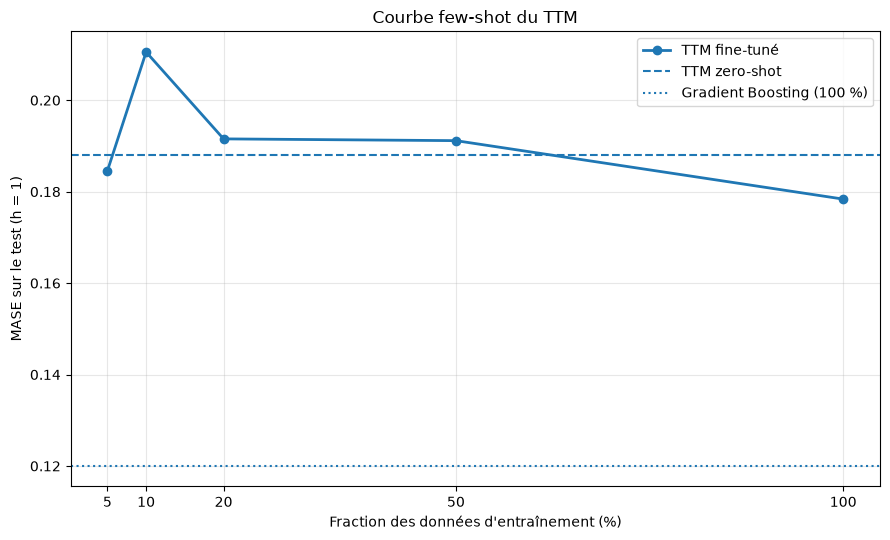


--- Tableau récapitulatif Q10 ---
 fraction_pct  n_train_windows         mae     mase
          5.0            133.0  922.052083 0.184551
         10.0           1897.0 1051.888057 0.210538
         20.0           5425.0  956.977977 0.191542
         50.0          16009.0  955.046654 0.191155
        100.0          29329.0  891.180000 0.178372

Figure : c:\Users\Said O\Desktop\Projets\TSFM_Wind_Forecasting\results\q10_fewshot\courbe_fewshot.png
Tableau : c:\Users\Said O\Desktop\Projets\TSFM_Wind_Forecasting\results\q10_fewshot\tableau_fewshot.csv
Durée : 0.65 s


In [43]:
# ============================================================
# Q10.7 — Courbe few-shot définitive
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

debut = perf_counter()

# Résultats des quatre expériences few-shot
lignes = []

for pct in [5, 10, 20, 50]:
    chemin = (
        DOSSIER_RESULTATS_Q10
        / f"metriques_{pct}pct.csv"
    )

    assert chemin.exists(), f"Fichier absent : {chemin}"

    metriques = pd.read_csv(chemin)
    lignes.append(metriques.iloc[0].to_dict())

# Résultat Q9 à 100 %, déjà évalué
# MAE conservée avec la précision disponible
mae_100 = 891.18
echelle_mase = 4996.19

lignes.append({
    "fraction": 1.0,
    "fraction_pct": 100,
    "n_train_windows": 29329,
    "n_test": 7561,
    "best_epoch": checkpoint_q9["epoch"],
    "mae": mae_100,
    "mase": mae_100 / echelle_mase
})

tableau_q10 = pd.DataFrame(lignes)
tableau_q10 = tableau_q10.sort_values(
    "fraction_pct"
).reset_index(drop=True)

# Références
mase_zero_shot = 939.88 / echelle_mase
mase_gb = 599.75 / echelle_mase

# Graphique
fig, ax = plt.subplots(figsize=(9, 5.5))

ax.plot(
    tableau_q10["fraction_pct"],
    tableau_q10["mase"],
    marker="o",
    linewidth=2,
    label="TTM fine-tuné"
)

ax.axhline(
    mase_zero_shot,
    linestyle="--",
    label="TTM zero-shot"
)

ax.axhline(
    mase_gb,
    linestyle=":",
    label="Gradient Boosting (100 %)"
)

ax.set_xlabel("Fraction des données d'entraînement (%)")
ax.set_ylabel("MASE sur le test (h = 1)")
ax.set_title("Courbe few-shot du TTM")
ax.set_xticks([5, 10, 20, 50, 100])
ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()

# Sauvegardes
chemin_figure = (
    DOSSIER_RESULTATS_Q10 / "courbe_fewshot.png"
)
chemin_tableau = (
    DOSSIER_RESULTATS_Q10 / "tableau_fewshot.csv"
)

fig.savefig(chemin_figure, dpi=200, bbox_inches="tight")
tableau_q10.to_csv(chemin_tableau, index=False)

plt.show()

print("\n--- Tableau récapitulatif Q10 ---")
print(
    tableau_q10[
        ["fraction_pct", "n_train_windows", "mae", "mase"]
    ].to_string(index=False)
)

print("\nFigure :", chemin_figure)
print("Tableau :", chemin_tableau)
print(f"Durée : {perf_counter() - debut:.2f} s")

### Q10 - Conclusion : courbe few-shot du TTM

On a étudié l'effet de la quantité de données d'entraînement sur les performances du TTM fine-tuné, en utilisant cinq fractions : 5 %, 10 %, 20 %, 50 % et 100 %.

Pour chaque fraction, on est reparti du modèle pré-entraîné d'origine et on a entraîné uniquement sa tête de prédiction, en conservant les mêmes hyperparamètres et les mêmes périodes de validation et de test.

Les MASE obtenus sur le test, à l'horizon d'une heure, sont respectivement :

| Fraction | MASE |
|---|---:|
| 5 % | 0,1978 |
| 10 % | 0,2105 |
| 20 % | 0,1915 |
| 50 % | 0,1912 |
| 100 % | 0,1784 |

La courbe few-shot n'est pas monotone. Le modèle devient moins précis entre 5 % et 10 %, puis ses performances s'améliorent progressivement.

Le fine-tuning ne dépasse le TTM zero-shot (MASE ≈ 0,1881) qu'avec 100 % des données parmi les fractions testées.

En revanche, aucune fraction ne permet d'atteindre les performances du Gradient Boosting entraîné sur l'ensemble des données (MASE ≈ 0,1200).

**On conclut donc que, dans notre protocole, le TTM fine-tuné ne devient pas compétitif avec le Gradient Boosting, même avec l'intégralité des données d'entraînement.**

D'un point de vue opérationnel, ces résultats montrent qu'il faut vérifier l'intérêt du fine-tuning avant de déployer un modèle de fondation sur un nouveau site disposant de peu d'historique. Le modèle zero-shot peut constituer une solution de départ intéressante.

Cette étude comporte néanmoins plusieurs limites : on utilise une seule série temporelle, une seule graine aléatoire et des fractions chronologiques emboîtées. Le nombre de mises à jour varie également avec la quantité de données.

Enfin, la sélection des checkpoints repose sur une perte de validation à 96 heures, alors que l'évaluation finale porte sur une heure. Une étude complémentaire pourrait examiner l'effet d'une sélection directement fondée sur le MASE de validation à l'horizon \(h=1\), de plusieurs graines aléatoires et d'une adaptation des hyperparamètres à la quantité de données disponibles.

Ces résultats illustrent que la réussite du fine-tuning dépend non seulement de la quantité d'historique, mais aussi de sa représentativité et du protocole d'apprentissage.

## Question 11 : Analyse des erreurs du meilleur modèle

### Objectif

Dans les questions précédentes, on a comparé plusieurs modèles de prévision de la production éolienne allemande à l'aide de la MAE et du MASE calculés sur l'ensemble de la période de test.

Le Gradient Boosting est le modèle le plus précis, avec une MAE de 599,75 MW et un MASE d'environ 0,120.

Cependant, ces métriques globales ne permettent pas de savoir si les erreurs sont réparties uniformément dans le temps.

On cherche donc à analyser les erreurs du Gradient Boosting selon deux dimensions temporelles :

- l'heure de la journée ;
- la saison de l'année.

On souhaite également identifier au moins une période où les prévisions sont particulièrement mauvaises et proposer une explication plausible.

### Méthodologie

Pour chaque observation du test, on calcule l'erreur absolue :

$$
e_t=|y_t-\widehat{y}_t|
$$

où $y_t$ représente la production réelle et $\widehat{y}_t$ la production prédite par le Gradient Boosting.

On regroupe ensuite les erreurs par heure de la journée, puis par saison météorologique.

Pour chaque groupe, on calcule la MAE moyenne et le nombre d'observations disponibles.

On représente les résultats à l'aide de graphiques, puis on examine les périodes où les erreurs sont les plus élevées.

### Précautions

Les horodatages sont exprimés en UTC. On conserve cette convention dans l'analyse.

Les saisons sont définies selon les mois calendaires : hiver (décembre à février), printemps (mars à mai), été (juin à août) et automne (septembre à novembre).

Les différences de MAE entre groupes seront d'abord décrites de manière exploratoire. Elles ne permettront pas, à elles seules, d'établir une relation causale entre l'heure, la saison et les erreurs du modèle.

### Q11.1 - Reconstitution du Gradient Boosting retenu

Le modèle Gradient Boosting entraîné lors de la question 4 n'a pas été sauvegardé. On doit donc le reconstruire avant de pouvoir analyser ses erreurs.

On reprend exactement la variante qui prédit la variation horaire de la production éolienne :

$$
\Delta y_t = y_t-y_{t-1}
$$

La prévision de production est ensuite reconstruite en ajoutant la variation prédite à la dernière valeur observée :

$$
\widehat y_t=y_{t-1}+\widehat{\Delta y_t}
$$

On utilise les mêmes variables calendaires, les mêmes retards et les mêmes hyperparamètres que dans la question 4.

Le modèle est entraîné uniquement sur les données d'entraînement. Les périodes de validation et de test ne sont pas utilisées pour ajuster ses paramètres.

Avant de commencer l'analyse des erreurs, on vérifie que la MAE obtenue sur le test est cohérente avec le résultat de référence de 599,75 MW.

On sauvegarde ensuite le modèle et les prédictions afin de rendre l'analyse reproductible.

In [46]:
# ============================================================
# Q11.1 — Reconstruire et sauvegarder le meilleur GBM
# ============================================================

from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import joblib

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

debut = perf_counter()

# ------------------------------------------------------------
# 1. Préparer les dossiers de sauvegarde
# ------------------------------------------------------------

dossier_modeles = PROJECT_DIR / "models"
dossier_resultats = PROJECT_DIR / "results" / "q11_erreurs"

dossier_modeles.mkdir(parents=True, exist_ok=True)
dossier_resultats.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. Reconstituer les variables de la Q4
# ------------------------------------------------------------

donnees_gb = data[["utc_timestamp", TARGET]].copy()

donnees_gb = (
    donnees_gb
    .sort_values("utc_timestamp")
    .reset_index(drop=True)
)

donnees_gb["hour"] = donnees_gb["utc_timestamp"].dt.hour
donnees_gb["dayofweek"] = donnees_gb["utc_timestamp"].dt.dayofweek
donnees_gb["month"] = donnees_gb["utc_timestamp"].dt.month

lags = [1, 2, 3, 24, 48, 168]

for lag in lags:
    donnees_gb[f"lag_{lag}"] = donnees_gb[TARGET].shift(lag)

donnees_gb["hour_sin"] = np.sin(
    2 * np.pi * donnees_gb["hour"] / 24
)

donnees_gb["hour_cos"] = np.cos(
    2 * np.pi * donnees_gb["hour"] / 24
)

donnees_gb["day_sin"] = np.sin(
    2 * np.pi * donnees_gb["dayofweek"] / 7
)

donnees_gb["day_cos"] = np.cos(
    2 * np.pi * donnees_gb["dayofweek"] / 7
)

FEATURES_Q11 = [
    "hour", "dayofweek", "month",
    "hour_sin", "hour_cos", "day_sin", "day_cos",
    "lag_1", "lag_2", "lag_3",
    "lag_24", "lag_48", "lag_168"
]

# Cible : variation entre deux heures consécutives
donnees_gb["delta_target"] = (
    donnees_gb[TARGET] - donnees_gb[TARGET].shift(1)
)

# ------------------------------------------------------------
# 3. Respecter le découpage chronologique initial
# ------------------------------------------------------------

fin_train = train["utc_timestamp"].max()
fin_validation = validation["utc_timestamp"].max()

train_delta_q11 = donnees_gb[
    donnees_gb["utc_timestamp"] <= fin_train
].copy()

test_delta_q11 = donnees_gb[
    donnees_gb["utc_timestamp"] > fin_validation
].copy()

colonnes_obligatoires = (
    FEATURES_Q11 + ["delta_target", TARGET, "lag_1"]
)

train_delta_q11 = train_delta_q11.dropna(
    subset=colonnes_obligatoires
)

test_delta_q11 = test_delta_q11.dropna(
    subset=colonnes_obligatoires
)

print("Lignes d'entraînement :", len(train_delta_q11))
print("Lignes de test :", len(test_delta_q11))
print("Variables explicatives :", len(FEATURES_Q11))

# ------------------------------------------------------------
# 4. Réentraîner le modèle de la Q4
# ------------------------------------------------------------

gb_delta_model_q11 = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    loss="squared_error",
    random_state=42
)

gb_delta_model_q11.fit(
    train_delta_q11[FEATURES_Q11],
    train_delta_q11["delta_target"]
)

# ------------------------------------------------------------
# 5. Reconstruire les prévisions de production
# ------------------------------------------------------------

variations_prevues = gb_delta_model_q11.predict(
    test_delta_q11[FEATURES_Q11]
)

productions_prevues = (
    test_delta_q11["lag_1"].to_numpy()
    + variations_prevues
)

productions_reelles = test_delta_q11[TARGET].to_numpy()

mae_gb_q11 = mean_absolute_error(
    productions_reelles,
    productions_prevues
)

print(f"\nMAE Gradient Boosting test : {mae_gb_q11:.2f} MW")
print("MAE de référence Q4 : 599.75 MW")

# ------------------------------------------------------------
# 6. Sauvegarder le modèle et les prédictions
# ------------------------------------------------------------

chemin_modele = (
    dossier_modeles / "gb_delta_q11.joblib"
)

joblib.dump(
    {
        "modele": gb_delta_model_q11,
        "variables": FEATURES_Q11,
        "lags": lags,
        "cible": TARGET,
        "mae_test": mae_gb_q11
    },
    chemin_modele
)

predictions_gb_q11 = pd.DataFrame({
    "utc_timestamp": test_delta_q11[
        "utc_timestamp"
    ].to_numpy(),
    "y_true": productions_reelles,
    "y_pred": productions_prevues
})

predictions_gb_q11["erreur"] = (
    predictions_gb_q11["y_true"]
    - predictions_gb_q11["y_pred"]
)

predictions_gb_q11["erreur_absolue"] = (
    predictions_gb_q11["erreur"].abs()
)

chemin_predictions = (
    dossier_resultats / "predictions_gb_test.csv"
)

predictions_gb_q11.to_csv(
    chemin_predictions,
    index=False
)

print("\nModèle sauvegardé :", chemin_modele)
print("Prédictions sauvegardées :", chemin_predictions)

print(
    f"\nDurée totale : "
    f"{perf_counter() - debut:.2f} secondes"
)

Lignes d'entraînement : 34823
Lignes de test : 7561
Variables explicatives : 13

MAE Gradient Boosting test : 599.75 MW
MAE de référence Q4 : 599.75 MW

Modèle sauvegardé : c:\Users\Said O\Desktop\Projets\TSFM_Wind_Forecasting\models\gb_delta_q11.joblib
Prédictions sauvegardées : c:\Users\Said O\Desktop\Projets\TSFM_Wind_Forecasting\results\q11_erreurs\predictions_gb_test.csv

Durée totale : 8.06 secondes


### Résultat : Reconstitution du Gradient Boosting

On a reconstruit le Gradient Boosting entraîné sur la variation horaire de la production éolienne, en reprenant les variables explicatives, les hyperparamètres et le découpage chronologique de la question 4.

Le modèle a été entraîné sur 34 823 observations exploitables, avec 13 variables explicatives.

Sur les 7 561 observations de test, on obtient une MAE de **599,75 MW**, identique à la valeur de référence de la question 4 à deux décimales.

Ce résultat confirme la cohérence de notre reconstruction. On peut désormais analyser les erreurs de ce modèle selon l'heure de la journée et la saison.

Le modèle entraîné et les prévisions horaires ont été sauvegardés pour permettre de reproduire les analyses sans nouvel entraînement.

### Q11.2 - Décomposition des erreurs par heure de la journée

On cherche à déterminer si la précision du Gradient Boosting varie selon l'heure de la journée.

Pour chaque heure comprise entre 0 h et 23 h, on regroupe les observations correspondantes de la période de test et on calcule leur erreur absolue moyenne (MAE).

On conserve les heures en UTC, conformément aux horodatages du jeu de données.

Cette analyse permet d'identifier les heures où le modèle présente les erreurs moyennes les plus importantes. Elle reste descriptive : une différence entre deux heures ne suffit pas à établir que l'heure elle-même est la cause des erreurs.

On calcule également le nombre d'observations par groupe pour vérifier que les comparaisons reposent sur des effectifs comparables.

In [47]:
# ============================================================
# Q11.2 — Erreurs du Gradient Boosting par heure
# ============================================================

from time import perf_counter
import pandas as pd

debut = perf_counter()

# ------------------------------------------------------------
# 1. Récupérer les prédictions sauvegardées
# ------------------------------------------------------------

chemin_predictions = (
    PROJECT_DIR
    / "results"
    / "q11_erreurs"
    / "predictions_gb_test.csv"
)

erreurs_q11 = pd.read_csv(
    chemin_predictions,
    parse_dates=["utc_timestamp"]
)

# ------------------------------------------------------------
# 2. Extraire l'heure de chaque observation
# ------------------------------------------------------------

erreurs_q11["heure"] = (
    erreurs_q11["utc_timestamp"].dt.hour
)

# ------------------------------------------------------------
# 3. Calculer les indicateurs par heure
# ------------------------------------------------------------

erreurs_par_heure = (
    erreurs_q11
    .groupby("heure")
    .agg(
        n_observations=("erreur_absolue", "size"),
        mae_mw=("erreur_absolue", "mean"),
        mediane_mw=("erreur_absolue", "median"),
        erreur_max_mw=("erreur_absolue", "max")
    )
    .reset_index()
)

# ------------------------------------------------------------
# 4. Afficher et sauvegarder les résultats
# ------------------------------------------------------------

print("--- Erreurs par heure (UTC) ---")

display(
    erreurs_par_heure.round(2)
)

heure_difficile = erreurs_par_heure.loc[
    erreurs_par_heure["mae_mw"].idxmax()
]

heure_facile = erreurs_par_heure.loc[
    erreurs_par_heure["mae_mw"].idxmin()
]

print(
    f"\nHeure avec la MAE la plus élevée : "
    f"{int(heure_difficile['heure']):02d} h UTC "
    f"({heure_difficile['mae_mw']:.2f} MW)"
)

print(
    f"Heure avec la MAE la plus faible : "
    f"{int(heure_facile['heure']):02d} h UTC "
    f"({heure_facile['mae_mw']:.2f} MW)"
)

chemin_sortie = (
    PROJECT_DIR
    / "results"
    / "q11_erreurs"
    / "erreurs_par_heure.csv"
)

erreurs_par_heure.to_csv(
    chemin_sortie,
    index=False
)

print(
    f"\nDurée : {perf_counter() - debut:.2f} s"
)

--- Erreurs par heure (UTC) ---


,heure,n_observations,mae_mw,mediane_mw,erreur_max_mw
0,0,315,433.66,304.77,3251.90
1,1,315,410.44,302.17,2040.43
2,2,315,410.07,287.96,2920.76
3,3,315,402.11,292.93,2109.16
4,4,315,459.86,334.78,2989.87
5,5,315,703.54,530.35,2925.11
6,6,315,731.83,509.65,3246.79
7,7,315,785.91,525.76,4834.01
8,8,315,672.97,506.68,4959.25
9,9,315,636.27,451.37,3618.38



Heure avec la MAE la plus élevée : 18 h UTC (856.33 MW)
Heure avec la MAE la plus faible : 03 h UTC (402.11 MW)

Durée : 0.10 s


### Résultats : Erreurs par heure de la journée

L'analyse porte sur les 7 561 prévisions horaires du Gradient Boosting pendant la période de test.

Chaque heure de la journée comporte 315 observations, sauf 23 h UTC qui en comporte 316. Les effectifs sont donc pratiquement identiques, ce qui facilite la comparaison des erreurs moyennes.

On constate que les performances du modèle varient selon l'heure de la journée.

La MAE la plus faible est obtenue à **3 h UTC (402,11 MW)**, tandis que la plus élevée est observée à **18 h UTC (856,33 MW)**. L'erreur moyenne à 18 h est ainsi environ 2,13 fois supérieure à celle de 3 h.

Deux périodes présentent des erreurs relativement importantes : le matin, entre 5 h et 9 h UTC, et la fin d'après-midi, entre 15 h et 19 h UTC.

La médiane des erreurs absolues est également élevée à 18 h (647,60 MW), ce qui suggère que cette difficulté ne s'explique pas uniquement par quelques observations extrêmes.

On relève toutefois une erreur individuelle maximale de 7 982,05 MW à 15 h UTC. Cette observation pourra être examinée plus précisément pour identifier une situation où le modèle échoue nettement.

Ces résultats montrent que la MAE globale de 599,75 MW masque des différences importantes selon l'heure.

À ce stade, on peut supposer que certaines variations horaires de la production éolienne sont plus difficiles à anticiper. Cette hypothèse devra être examinée en étudiant les variations réelles de production et les erreurs du modèle.

L'analyse reste descriptive et ne permet pas encore d'attribuer ces différences à une cause météorologique précise.

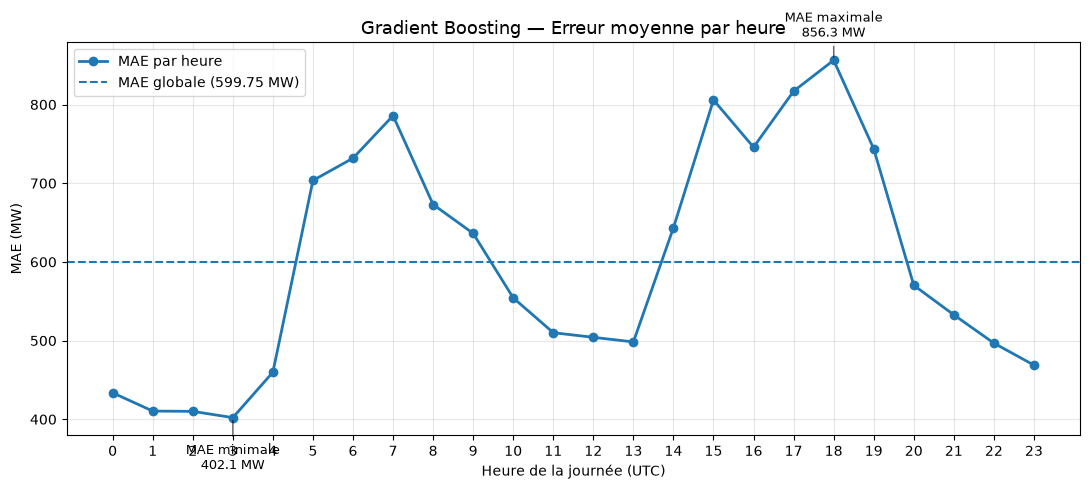

Graphique sauvegardé : c:\Users\Said O\Desktop\Projets\TSFM_Wind_Forecasting\results\q11_erreurs\mae_par_heure.png
Durée : 0.69 s


In [48]:
# ============================================================
# Q11.2 — Graphique de la MAE par heure de la journée
# ============================================================

import matplotlib.pyplot as plt
from time import perf_counter

debut = perf_counter()

fig, ax = plt.subplots(figsize=(11, 5))

# Courbe des erreurs horaires
ax.plot(
    erreurs_par_heure["heure"],
    erreurs_par_heure["mae_mw"],
    marker="o",
    linewidth=2,
    label="MAE par heure"
)

# Référence : erreur globale du Gradient Boosting
ax.axhline(
    y=mae_gb_q11,
    linestyle="--",
    linewidth=1.5,
    label=f"MAE globale ({mae_gb_q11:.2f} MW)"
)

# Repérer les heures extrêmes
indice_max = erreurs_par_heure["mae_mw"].idxmax()
indice_min = erreurs_par_heure["mae_mw"].idxmin()

for indice, etiquette in [
    (indice_max, "MAE maximale"),
    (indice_min, "MAE minimale")
]:
    ligne = erreurs_par_heure.loc[indice]

    ax.annotate(
        f"{etiquette}\n{ligne['mae_mw']:.1f} MW",
        xy=(ligne["heure"], ligne["mae_mw"]),
        xytext=(0, 17 if indice == indice_max else -37),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        arrowprops=dict(arrowstyle="-", alpha=0.6)
    )

ax.set_title(
    "Gradient Boosting — Erreur moyenne par heure",
    fontsize=13
)

ax.set_xlabel("Heure de la journée (UTC)")
ax.set_ylabel("MAE (MW)")

ax.set_xticks(range(24))
ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()

# Sauvegarde
chemin_graphique = (
    PROJECT_DIR
    / "results"
    / "q11_erreurs"
    / "mae_par_heure.png"
)

fig.savefig(
    chemin_graphique,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Graphique sauvegardé :", chemin_graphique)
print(
    f"Durée : {perf_counter() - debut:.2f} s"
)

### Interprétation du graphique - MAE par heure

Le graphique représente la MAE du Gradient Boosting pour chacune des 24 heures de la journée, sur la période de test.

On observe deux périodes où les erreurs sont particulièrement élevées : entre 5 h et 9 h UTC, puis entre 14 h et 19 h UTC.

La MAE atteint son maximum à 18 h UTC (856,33 MW), alors qu'elle est minimale à 3 h UTC (402,11 MW). L'erreur moyenne à 18 h est donc environ 2,13 fois supérieure à celle de 3 h.

La ligne horizontale correspondant à la MAE globale (599,75 MW) permet de repérer les heures où le modèle est moins précis que sa performance moyenne sur l'ensemble du test.

Cette analyse montre que la métrique globale masque des variations importantes de précision au cours de la journée.

Une hypothèse possible est que certaines périodes présentent des variations de production plus difficiles à prévoir à partir des seules valeurs passées. Toutefois, le graphique ne permet pas de vérifier cette explication. On devra examiner les variations réelles de production et les situations d'erreur importante pour aller plus loin.

### Q11.3 - Décomposition des erreurs par saison

Après avoir étudié les erreurs selon l'heure de la journée, on cherche à déterminer si les performances du Gradient Boosting varient selon la saison.

On définit les saisons météorologiques à partir des mois calendaires : hiver (décembre à février), printemps (mars à mai), été (juin à août) et automne (septembre à novembre).

Pour chaque saison, on calcule la MAE, la médiane des erreurs absolues, l'erreur maximale et le nombre d'observations.

Cette analyse permet d'identifier les saisons pendant lesquelles les prévisions sont les moins précises.

On gardera à l'esprit que les différences de production éolienne entre saisons peuvent influencer les erreurs exprimées en MW. Une saison présentant une MAE plus élevée n'est donc pas nécessairement plus difficile à prévoir en termes relatifs.

Les résultats seront interprétés de manière descriptive, sans conclure à une relation causale entre la saison et les erreurs.

In [49]:
# ============================================================
# Q11.3 — Erreurs du Gradient Boosting par saison
# ============================================================

from time import perf_counter
import pandas as pd

debut = perf_counter()

# ------------------------------------------------------------
# 1. Définir les saisons météorologiques
# ------------------------------------------------------------

def definir_saison(mois):
    if mois in [12, 1, 2]:
        return "Hiver"
    elif mois in [3, 4, 5]:
        return "Printemps"
    elif mois in [6, 7, 8]:
        return "Été"
    else:
        return "Automne"

erreurs_q11["mois"] = erreurs_q11["utc_timestamp"].dt.month

erreurs_q11["saison"] = (
    erreurs_q11["mois"].apply(definir_saison)
)

# ------------------------------------------------------------
# 2. Calculer les indicateurs par saison
# ------------------------------------------------------------

ordre_saisons = [
    "Hiver", "Printemps", "Été", "Automne"
]

erreurs_par_saison = (
    erreurs_q11
    .groupby("saison")
    .agg(
        n_observations=("erreur_absolue", "size"),
        mae_mw=("erreur_absolue", "mean"),
        mediane_mw=("erreur_absolue", "median"),
        erreur_max_mw=("erreur_absolue", "max")
    )
    .reindex(ordre_saisons)
    .reset_index()
)

# ------------------------------------------------------------
# 3. Afficher et sauvegarder les résultats
# ------------------------------------------------------------

print("--- Erreurs par saison ---")

display(
    erreurs_par_saison.round(2)
)

saison_difficile = erreurs_par_saison.loc[
    erreurs_par_saison["mae_mw"].idxmax()
]

saison_facile = erreurs_par_saison.loc[
    erreurs_par_saison["mae_mw"].idxmin()
]

print(
    f"\nSaison avec la MAE la plus élevée : "
    f"{saison_difficile['saison']} "
    f"({saison_difficile['mae_mw']:.2f} MW)"
)

print(
    f"Saison avec la MAE la plus faible : "
    f"{saison_facile['saison']} "
    f"({saison_facile['mae_mw']:.2f} MW)"
)

chemin_sortie = (
    PROJECT_DIR
    / "results"
    / "q11_erreurs"
    / "erreurs_par_saison.csv"
)

erreurs_par_saison.to_csv(
    chemin_sortie,
    index=False
)

print(
    f"\nDurée : {perf_counter() - debut:.2f} s"
)

--- Erreurs par saison ---


,saison,n_observations,mae_mw,mediane_mw,erreur_max_mw
0,Hiver,2184,686.12,505.87,3877.92
1,Printemps,2208,658.22,449.42,7982.05
2,Été,2208,497.82,348.60,4624.59
3,Automne,961,503.30,346.07,3605.02



Saison avec la MAE la plus élevée : Hiver (686.12 MW)
Saison avec la MAE la plus faible : Été (497.82 MW)

Durée : 0.03 s


### Résultats : Décomposition des erreurs par saison

L'analyse des erreurs du Gradient Boosting met en évidence des différences de précision selon la saison.

La MAE la plus élevée est observée en hiver (686,12 MW), suivie du printemps (658,22 MW). Les erreurs moyennes sont plus faibles en automne (503,30 MW) et en été (497,82 MW).

La MAE hivernale est environ 37,8 % supérieure à celle de l'été. La médiane des erreurs absolues est également plus élevée en hiver (505,87 MW), ce qui confirme que les erreurs ne sont pas uniquement dues à quelques observations extrêmes.

Le printemps présente toutefois l'erreur individuelle maximale de toute l'analyse, avec 7 982,05 MW.

Les effectifs sont proches pour l'hiver, le printemps et l'été, mais l'automne ne comporte que 961 observations. Les comparaisons impliquant l'automne doivent donc être interprétées avec davantage de prudence.

Ces résultats montrent que les performances du Gradient Boosting varient selon la saison.

Une explication possible serait que certaines saisons présentent une production éolienne plus variable, avec des changements rapides plus difficiles à anticiper à partir des seules valeurs passées.

Cette hypothèse reste à vérifier. Les différences observées peuvent également être liées aux niveaux de production ou à la période particulière couverte par notre jeu de test.

L'analyse saisonnière reste donc descriptive et ne permet pas, à elle seule, d'établir une relation causale entre la saison et les erreurs du modèle.

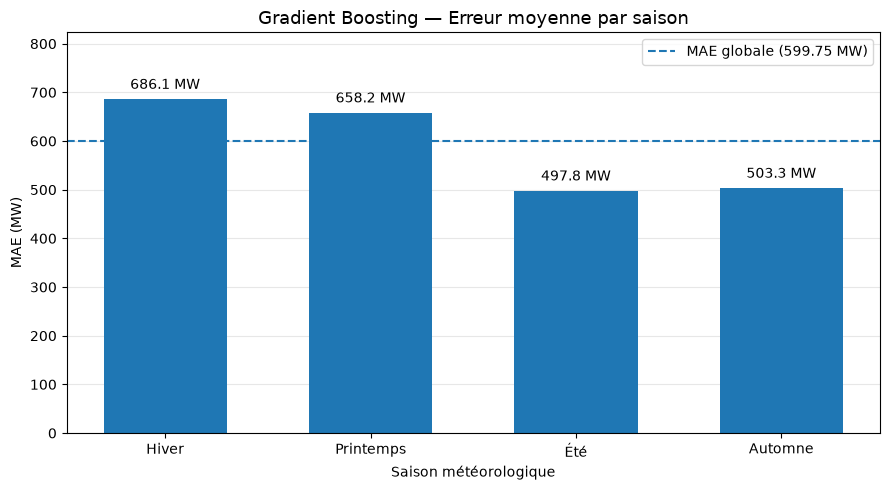

Graphique sauvegardé : c:\Users\Said O\Desktop\Projets\TSFM_Wind_Forecasting\results\q11_erreurs\mae_par_saison.png
Durée : 0.42 s


In [51]:
# ============================================================
# Q11.3 — Graphique de la MAE par saison
# ============================================================

import matplotlib.pyplot as plt
from time import perf_counter

debut = perf_counter()

fig, ax = plt.subplots(figsize=(9, 5))

# Diagramme en barres
barres = ax.bar(
    erreurs_par_saison["saison"],
    erreurs_par_saison["mae_mw"],
    width=0.6
)

# MAE globale de référence
ax.axhline(
    y=mae_gb_q11,
    linestyle="--",
    linewidth=1.5,
    label=f"MAE globale ({mae_gb_q11:.2f} MW)"
)

# Afficher les valeurs au-dessus des barres
for barre in barres:
    hauteur = barre.get_height()

    ax.annotate(
        f"{hauteur:.1f} MW",
        xy=(
            barre.get_x() + barre.get_width() / 2,
            hauteur
        ),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10
    )

ax.set_title(
    "Gradient Boosting — Erreur moyenne par saison",
    fontsize=13
)

ax.set_xlabel("Saison météorologique")
ax.set_ylabel("MAE (MW)")
ax.set_ylim(0, erreurs_par_saison["mae_mw"].max() * 1.2)

ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.legend()

fig.tight_layout()

# Sauvegarde du graphique
chemin_graphique = (
    PROJECT_DIR
    / "results"
    / "q11_erreurs"
    / "mae_par_saison.png"
)

fig.savefig(
    chemin_graphique,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Graphique sauvegardé :", chemin_graphique)
print(
    f"Durée : {perf_counter() - debut:.2f} s"
)

### Interprétation du graphique saisonnier

Le diagramme en barres confirme que les erreurs du Gradient Boosting varient selon la saison.

L'hiver présente la MAE la plus élevée (686,12 MW), suivi du printemps (658,22 MW). Ces deux saisons dépassent la MAE globale de 599,75 MW.

À l'inverse, l'été (497,82 MW) et l'automne (503,30 MW) présentent des erreurs moyennes inférieures à la MAE globale.

La MAE hivernale est supérieure de 188,30 MW à celle de l'été, soit environ 37,8 %.

Ces différences pourraient être associées à des variations saisonnières du niveau ou de la dynamique de la production éolienne. Toutefois, les résultats ne permettent pas encore de confirmer cette hypothèse.

L'automne est représenté par un nombre d'observations plus faible que les autres saisons. La comparaison doit donc être interprétée avec prudence.

Cette analyse complète la décomposition horaire : les erreurs du meilleur modèle dépendent de la période considérée, ce qui justifie une étude plus détaillée des situations où ses prévisions sont particulièrement mauvaises.

### Q11.4 - Analyse croisée des erreurs par heure et par saison

Les analyses précédentes ont montré que les erreurs du Gradient Boosting varient selon l'heure de la journée et selon la saison.

On cherche maintenant à déterminer si les heures présentant les erreurs les plus importantes sont identiques pendant toutes les saisons.

Pour cela, on regroupe les observations selon deux critères : la saison météorologique et l'heure UTC.

Pour chaque combinaison, on calcule la MAE :

$$
\operatorname{MAE}(h,s)
=
\frac{1}{n_{h,s}}
\sum_{\substack{t:\,\operatorname{heure}(t)=h\\
\operatorname{saison}(t)=s}}
|y_t-\widehat y_t|
$$

où $n_{h,s}$ représente le nombre d'observations appartenant à l'heure $h$ et à la saison $s$.

On représente ensuite les résultats sous la forme d'une carte thermique.

Cette visualisation permettra de repérer les combinaisons heure-saison où les erreurs sont particulièrement importantes et de sélectionner une situation à examiner plus précisément.

--- Dix combinaisons les plus difficiles ---


,saison,heure,n_observations,mae_mw
66,Printemps,18,92,1092.07
39,Hiver,15,91,1066.80
40,Hiver,16,91,1052.38
55,Printemps,7,92,1046.02
67,Printemps,19,92,986.91
41,Hiver,17,91,952.13
63,Printemps,15,92,878.98
54,Printemps,6,92,857.56
65,Printemps,17,92,832.90
56,Printemps,8,92,832.07



Effectifs par saison et par heure :


heure,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
saison,,,,,,,,,,,,,,,,,,,,,
Hiver,91,91,91,91,91,91,91,91,91,91,...,91,91,91,91,91,91,91,91,91,91
Printemps,92,92,92,92,92,92,92,92,92,92,...,92,92,92,92,92,92,92,92,92,92
Été,92,92,92,92,92,92,92,92,92,92,...,92,92,92,92,92,92,92,92,92,92
Automne,40,40,40,40,40,40,40,40,40,40,...,40,40,40,40,40,40,40,40,40,41


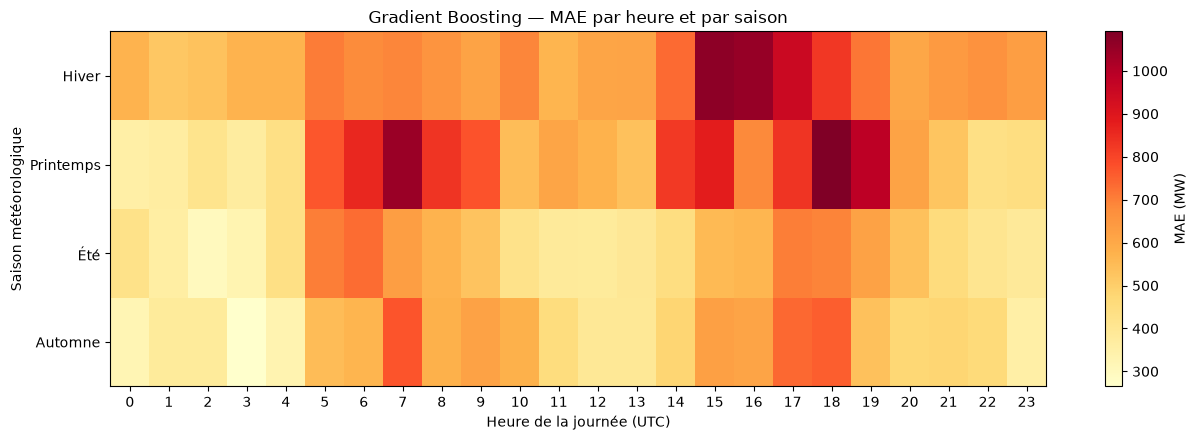


Durée : 0.72 s


In [52]:
# ============================================================
# Q11.4 — Carte thermique des erreurs par heure et saison
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
from time import perf_counter

debut = perf_counter()

# ------------------------------------------------------------
# 1. Calculer la MAE par heure et par saison
# ------------------------------------------------------------

mae_heure_saison = (
    erreurs_q11
    .groupby(["saison", "heure"])["erreur_absolue"]
    .mean()
    .unstack("heure")
    .reindex(ordre_saisons)
)

effectifs_heure_saison = (
    erreurs_q11
    .groupby(["saison", "heure"])["erreur_absolue"]
    .size()
    .unstack("heure")
    .reindex(ordre_saisons)
)

# ------------------------------------------------------------
# 2. Tracer la carte thermique
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 4.5))

image = ax.imshow(
    mae_heure_saison.to_numpy(),
    aspect="auto",
    cmap="YlOrRd"
)

ax.set_xticks(np.arange(24))
ax.set_xticklabels(mae_heure_saison.columns)

ax.set_yticks(np.arange(len(ordre_saisons)))
ax.set_yticklabels(ordre_saisons)

ax.set_xlabel("Heure de la journée (UTC)")
ax.set_ylabel("Saison météorologique")

ax.set_title(
    "Gradient Boosting — MAE par heure et par saison"
)

barre_couleur = fig.colorbar(image, ax=ax)
barre_couleur.set_label("MAE (MW)")

fig.tight_layout()

# ------------------------------------------------------------
# 3. Identifier la combinaison la plus difficile
# ------------------------------------------------------------

tableau_combinaisons = (
    erreurs_q11
    .groupby(["saison", "heure"])
    .agg(
        n_observations=("erreur_absolue", "size"),
        mae_mw=("erreur_absolue", "mean")
    )
    .reset_index()
    .sort_values("mae_mw", ascending=False)
)

print("--- Dix combinaisons les plus difficiles ---")

display(
    tableau_combinaisons.head(10).round(2)
)

print("\nEffectifs par saison et par heure :")
display(effectifs_heure_saison)

# ------------------------------------------------------------
# 4. Sauvegarder les résultats
# ------------------------------------------------------------

dossier_q11 = (
    PROJECT_DIR / "results" / "q11_erreurs"
)

fig.savefig(
    dossier_q11 / "mae_heure_saison.png",
    dpi=200,
    bbox_inches="tight"
)

tableau_combinaisons.to_csv(
    dossier_q11 / "mae_heure_saison.csv",
    index=False
)

plt.show()

print(
    f"\nDurée : {perf_counter() - debut:.2f} s"
)

### Interprétation de la carte thermique heure×saison

La carte thermique met en évidence des différences de précision du Gradient Boosting selon les combinaisons entre heure de la journée et saison météorologique.

La combinaison présentant la MAE la plus élevée est le printemps à 18 h UTC, avec **1 092,07 MW** sur 92 observations. Cette valeur représente environ 1,82 fois la MAE globale du modèle (599,75 MW).

Au printemps, deux périodes difficiles apparaissent : le matin autour de 7 h UTC et la fin d'après-midi autour de 18 h UTC.

En hiver, les erreurs les plus importantes se concentrent principalement entre 15 h et 17 h UTC, avec une MAE de 1 066,80 MW à 15 h.

En été et en automne, les erreurs moyennes sont généralement plus faibles, même si certaines heures présentent des difficultés.

Ces résultats montrent que les variations de précision selon l'heure ne sont pas identiques d'une saison à l'autre.

On peut supposer que certaines combinaisons heure–saison correspondent à des dynamiques de production plus difficiles à anticiper. Cette hypothèse devra toutefois être examinée à partir des variations réelles de production.

La carte thermique reste une analyse descriptive. Elle ne permet pas d'attribuer directement les erreurs à des conditions météorologiques particulières.

### Q11.5 - Identification d'une situation d'échec du modèle

Après avoir analysé les erreurs moyennes par heure et par saison, on cherche à identifier une situation précise où le Gradient Boosting échoue nettement.

On retient d'abord l'observation présentant l'erreur absolue maximale sur la période de test.

Pour comprendre cet échec, on examine la date de l'événement, la production réelle, la production prédite et les variations horaires de la production autour de cette observation.

On cherche notamment à vérifier si l'erreur importante coïncide avec une variation rapide de production que le modèle n'a pas correctement anticipée.

Cette analyse permettra de proposer une explication fondée sur les données observées, tout en distinguant les constats des hypothèses qui nécessiteraient des informations supplémentaires, notamment météorologiques.

In [53]:
# ============================================================
# Q11.5 — Identifier l'erreur maximale du Gradient Boosting
# ============================================================

from time import perf_counter
import pandas as pd

debut = perf_counter()

# ------------------------------------------------------------
# 1. Repérer l'observation avec l'erreur maximale
# ------------------------------------------------------------

indice_echec = erreurs_q11["erreur_absolue"].idxmax()

evenement_echec = erreurs_q11.loc[indice_echec]

date_echec = evenement_echec["utc_timestamp"]

print("--- Événement présentant l'erreur maximale ---")

print("Date UTC :", date_echec)

print(
    f"Production réelle : "
    f"{evenement_echec['y_true']:.2f} MW"
)

print(
    f"Production prédite : "
    f"{evenement_echec['y_pred']:.2f} MW"
)

print(
    f"Erreur signée : "
    f"{evenement_echec['erreur']:.2f} MW"
)

print(
    f"Erreur absolue : "
    f"{evenement_echec['erreur_absolue']:.2f} MW"
)

print("Saison :", evenement_echec["saison"])
print("Heure UTC :", evenement_echec["heure"])

# ------------------------------------------------------------
# 2. Examiner les 12 heures avant et après l'événement
# ------------------------------------------------------------

debut_fenetre = date_echec - pd.Timedelta(hours=12)
fin_fenetre = date_echec + pd.Timedelta(hours=12)

contexte_echec = erreurs_q11.loc[
    (erreurs_q11["utc_timestamp"] >= debut_fenetre)
    & (erreurs_q11["utc_timestamp"] <= fin_fenetre)
].copy()

# Variation horaire de production observée
contexte_echec["variation_reelle_mw"] = (
    contexte_echec["y_true"].diff()
)

# Variation horaire des prévisions
contexte_echec["variation_predite_mw"] = (
    contexte_echec["y_pred"].diff()
)

print("\n--- Contexte autour de l'événement ---")

display(
    contexte_echec[
        [
            "utc_timestamp",
            "y_true",
            "y_pred",
            "erreur",
            "erreur_absolue",
            "variation_reelle_mw",
            "variation_predite_mw"
        ]
    ].round(2)
)

# ------------------------------------------------------------
# 3. Sauvegarder le contexte
# ------------------------------------------------------------

chemin_contexte = (
    PROJECT_DIR
    / "results"
    / "q11_erreurs"
    / "contexte_erreur_maximale.csv"
)

contexte_echec.to_csv(
    chemin_contexte,
    index=False
)

print("\nContexte sauvegardé :", chemin_contexte)

print(
    f"Durée : {perf_counter() - debut:.2f} s"
)

--- Événement présentant l'erreur maximale ---
Date UTC : 2020-04-13 15:00:00+00:00
Production réelle : 21279.00 MW
Production prédite : 13296.95 MW
Erreur signée : 7982.05 MW
Erreur absolue : 7982.05 MW
Saison : Printemps
Heure UTC : 15

--- Contexte autour de l'événement ---


C:\Users\Said O\AppData\Local\Temp\ipykernel_21588\1957141680.py:82: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,utc_timestamp,y_true,y_pred,erreur,erreur_absolue,variation_reelle_mw,variation_predite_mw
3460,2020-04-13 03:00:00+00:00,17139.0,17027.34,111.66,111.66,NaN,NaN
3461,2020-04-13 04:00:00+00:00,17842.0,17629.99,212.01,212.01,703.0,602.65
3462,2020-04-13 05:00:00+00:00,18019.0,18100.12,-81.12,81.12,177.0,470.13
3463,2020-04-13 06:00:00+00:00,18873.0,18035.54,837.46,837.46,854.0,-64.58
3464,2020-04-13 07:00:00+00:00,19497.0,19037.13,459.87,459.87,624.0,1001.59
3465,2020-04-13 08:00:00+00:00,20360.0,19819.30,540.70,540.70,863.0,782.18
3466,2020-04-13 09:00:00+00:00,20953.0,20395.72,557.28,557.28,593.0,576.42
3467,2020-04-13 10:00:00+00:00,21185.0,21189.71,-4.71,4.71,232.0,793.99
3468,2020-04-13 11:00:00+00:00,17621.0,21190.14,-3569.14,3569.14,-3564.0,0.43
3469,2020-04-13 12:00:00+00:00,14067.0,16813.76,-2746.76,2746.76,-3554.0,-4376.37



Contexte sauvegardé : c:\Users\Said O\Desktop\Projets\TSFM_Wind_Forecasting\results\q11_erreurs\contexte_erreur_maximale.csv
Durée : 0.05 s


### Résultats : Identification d'une situation d'échec

L'erreur absolue maximale du Gradient Boosting est observée le **13 avril 2020 à 15 h UTC**, pendant le printemps.

À cette heure, la production réelle atteint 21 279 MW, alors que le modèle prévoit 13 296,95 MW. L'erreur absolue est donc de **7 982,05 MW**, soit environ 13,3 fois la MAE globale de 599,75 MW.

Pour comprendre cet échec, on examine les variations horaires de production autour de l'événement.

Entre 14 h et 15 h UTC, la production réelle augmente brutalement de 7 804 MW. En revanche, le modèle anticipe une variation de seulement −178,05 MW par rapport à la production réelle observée à 14 h.

Le Gradient Boosting ne parvient donc pas à anticiper ce changement brutal de production.

On observe également plusieurs variations importantes pendant les heures précédentes, notamment deux diminutions successives d'environ 3 500 MW entre 10 h et 12 h UTC.

Ces résultats suggèrent que le modèle rencontre des difficultés lorsque la dynamique de production change rapidement.

Cette explication est cohérente avec les variables utilisées : le Gradient Boosting repose principalement sur les productions passées et le calendrier, sans disposer de prévisions météorologiques explicites.

Toutefois, les données ne permettent pas d'établir la cause physique de cet événement. Il pourrait être lié à une évolution météorologique rapide, à un phénomène opérationnel ou à une particularité des données.

On retient donc comme constat que le modèle échoue à anticiper une variation horaire extrême, sans attribuer cette variation à une cause précise non vérifiée.

### Q11.6 - Visualisation d'une situation d'échec

On représente la production réelle et la production prévue par le Gradient Boosting sur une fenêtre de 12 heures avant et après l'événement du 13 avril 2020 à 15 h UTC.

On met en évidence l'heure de l'erreur maximale.

L'objectif est de visualiser la réaction du modèle face aux changements rapides de production et de comprendre pourquoi l'erreur devient particulièrement importante à cette heure.

On rappelle que les prévisions du Gradient Boosting sont calculées à une heure d'avance, en utilisant les observations réelles disponibles jusqu'à l'heure précédente. Le graphique ne représente donc pas une trajectoire de prévision multi-horizon réalisée à partir d'une seule date d'origine.

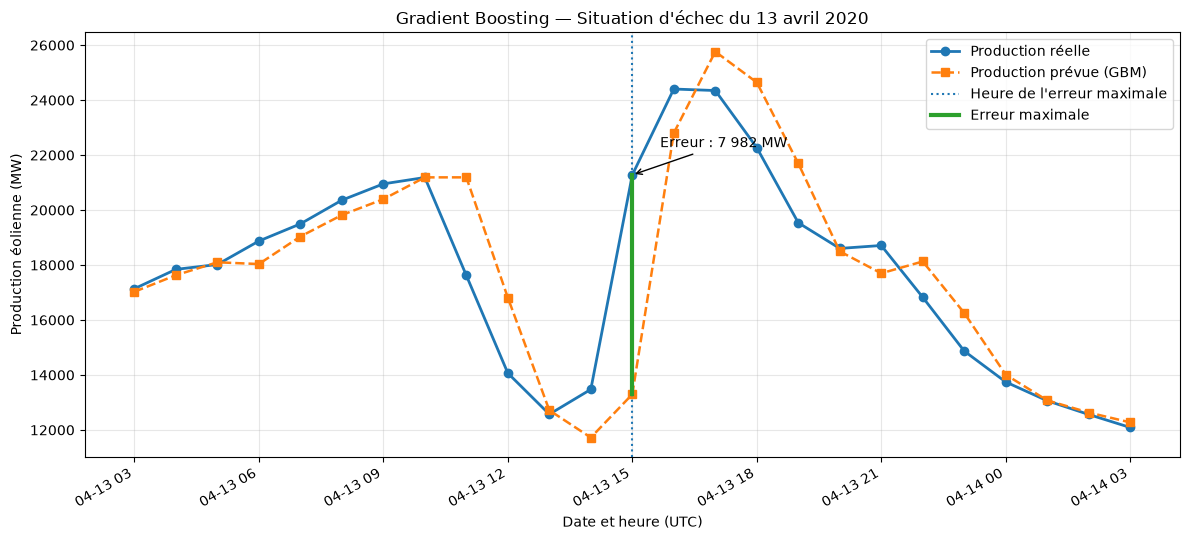

Graphique sauvegardé : c:\Users\Said O\Desktop\Projets\TSFM_Wind_Forecasting\results\q11_erreurs\situation_echec_2020_04_13.png
Durée : 0.65 s


In [54]:
# ============================================================
# Q11.6 — Graphique de la situation d'échec
# ============================================================

import matplotlib.pyplot as plt
from time import perf_counter

debut = perf_counter()

fig, ax = plt.subplots(figsize=(12, 5.5))

# Production réelle
ax.plot(
    contexte_echec["utc_timestamp"],
    contexte_echec["y_true"],
    marker="o",
    linewidth=2,
    label="Production réelle"
)

# Production prévue
ax.plot(
    contexte_echec["utc_timestamp"],
    contexte_echec["y_pred"],
    marker="s",
    linewidth=1.8,
    linestyle="--",
    label="Production prévue (GBM)"
)

# Identifier l'heure de l'erreur maximale
ax.axvline(
    date_echec,
    linestyle=":",
    linewidth=1.5,
    label="Heure de l'erreur maximale"
)

# Mettre en évidence l'écart entre réel et prévu
ax.plot(
    [date_echec, date_echec],
    [
        evenement_echec["y_pred"],
        evenement_echec["y_true"]
    ],
    linewidth=3,
    label="Erreur maximale"
)

ax.annotate(
    "Erreur : 7 982 MW",
    xy=(date_echec, evenement_echec["y_true"]),
    xytext=(20, 20),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->"),
    fontsize=10
)

ax.set_title(
    "Gradient Boosting — Situation d'échec du 13 avril 2020"
)

ax.set_xlabel("Date et heure (UTC)")
ax.set_ylabel("Production éolienne (MW)")

ax.grid(alpha=0.3)
ax.legend()

fig.autofmt_xdate()
fig.tight_layout()

# Sauvegarde
chemin_graphique = (
    PROJECT_DIR
    / "results"
    / "q11_erreurs"
    / "situation_echec_2020_04_13.png"
)

fig.savefig(
    chemin_graphique,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Graphique sauvegardé :", chemin_graphique)
print(
    f"Durée : {perf_counter() - debut:.2f} s"
)

### Interprétation du graphique - Situation d'échec

Le graphique compare la production éolienne réelle et les prévisions du Gradient Boosting autour du 13 avril 2020 à 15 h UTC.

Avant l'événement, le modèle suit globalement l'évolution de la production, malgré plusieurs écarts pendant la phase de diminution observée en milieu de journée.

À 15 h UTC, la production réelle augmente brutalement, passant de 13 475 MW à 21 279 MW en une heure, soit une hausse de 7 804 MW.

Le Gradient Boosting prévoit seulement 13 296,95 MW. Il anticipe donc une légère diminution de 178,05 MW par rapport à la dernière production réelle observée.

L'erreur absolue atteint ainsi **7 982,05 MW**, soit environ 13,3 fois la MAE globale du modèle.

À 16 h UTC, la prévision se rapproche de nouveau de la production réelle. Le modèle utilise en effet la dernière observation réelle disponible pour chaque nouvelle prévision à une heure d'avance.

Cette situation met en évidence une limite du Gradient Boosting : bien qu'il fournisse de bonnes performances moyennes, il peut manquer des changements brusques de la dynamique de production.

Une explication plausible est que les variables retardées et calendaires ne contiennent pas suffisamment d'informations pour anticiper certaines variations extrêmes.

Cette interprétation reste une hypothèse méthodologique. Sans données météorologiques ou opérationnelles complémentaires, on ne peut pas déterminer la cause physique de l'événement.

## Conclusion (Question 11) : Analyse des erreurs du meilleur modèle

Dans cette question, on a étudié les erreurs du Gradient Boosting, qui est le modèle ayant obtenu les meilleures performances sur la période de test, avec une MAE de **599,75 MW** et un MASE d'environ **0,120**.

L'objectif était de dépasser les métriques globales pour comprendre à quels moments les prévisions deviennent moins précises.

### 1. Analyse par heure de la journée

Les erreurs varient sensiblement selon l'heure UTC.

La MAE minimale est observée à 3 h UTC (402,11 MW), tandis que la MAE maximale atteint 856,33 MW à 18 h UTC.

Deux périodes apparaissent particulièrement difficiles : le matin, autour de 7 h UTC, et la fin d'après-midi, autour de 18 h UTC.

### 2. Analyse par saison

Les erreurs sont plus importantes en hiver (686,12 MW) et au printemps (658,22 MW) qu'en été (497,82 MW) et en automne (503,30 MW).

La MAE hivernale est environ 37,8 % supérieure à celle de l'été.

Ces différences peuvent être liées au niveau ou à la variabilité de la production, mais les données disponibles ne permettent pas d'en établir la cause.

### 3. Analyse croisée heure×saison

La carte thermique montre que les heures les plus difficiles ne sont pas identiques selon la saison.

La combinaison présentant la MAE la plus élevée est le printemps à 18 h UTC, avec 1 092,07 MW sur 92 observations.

En hiver, les erreurs sont particulièrement importantes entre 15 h et 17 h UTC.

Cette analyse montre que les variations horaires et saisonnières des erreurs doivent être étudiées conjointement.

### 4. Identification d'une situation d'échec

L'erreur absolue maximale est observée le 13 avril 2020 à 15 h UTC.

La production réelle augmente alors de 7 804 MW en une heure, tandis que le modèle prévoit une légère diminution de 178,05 MW.

L'erreur atteint **7 982,05 MW**, soit environ 13,3 fois la MAE globale.

Cet événement illustre la difficulté du Gradient Boosting à anticiper certaines variations extrêmes de production à partir des seules informations historiques et calendaires.

### 5. Enseignements et limites

Cette analyse montre qu'une bonne performance globale ne garantit pas une précision homogène dans toutes les situations.

Le Gradient Boosting est performant en moyenne, mais il présente des erreurs plus élevées à certaines heures, pendant certaines saisons et lors de variations horaires exceptionnelles.

Plusieurs pistes d'amélioration peuvent être envisagées :

- intégrer des variables météorologiques pertinentes, notamment des prévisions de vent disponibles au moment de la prédiction ;
- étudier spécifiquement les périodes de forte variation de production ;
- comparer les performances sur plusieurs années et plusieurs sites ;
- compléter la MAE globale par des indicateurs décrivant les erreurs extrêmes ;
- étudier la stabilité statistique des différences entre groupes temporels.

Ces pistes constituent des prolongements possibles et n'ont pas été testées dans cette question.

**En conclusion**, la question 11 montre l'intérêt d'une analyse détaillée des erreurs pour comprendre les limites opérationnelles d'un modèle de prévision. Elle permet de passer d'une simple comparaison de performances à une réflexion sur la robustesse, la fiabilité et les conditions d'utilisation du modèle.

# Références et ressources 
1. Ekambaram, V., et al. (2024).
   Tiny Time Mixers (TTMs): Fast pre-trained models
   for enhanced zero/few-shot forecasting of multivariate
   time series.
   https://arxiv.org/abs/2401.03955

2. Ansari, A. F., et al. (2024).
   Chronos: Learning the language of time series.
   https://arxiv.org/abs/2403.07815

3. Zeng, A., et al. (2023).
   Are transformers effective for time series forecasting?
   *Proceedings of the AAAI Conference on Artificial
   Intelligence, 37*(9), 11121–11128.
   https://doi.org/10.1609/aaai.v37i9.26317

4. Oreshkin, B. N., et al. (2020).
   N-BEATS: Neural basis expansion analysis for
   interpretable time series forecasting.
   *International Conference on Learning
   Representations (ICLR)*.
   https://arxiv.org/abs/1905.10437